<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-04/lab-012-onsager.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 012 
<hr/>

# Lab 012 — Onsager's exact solution of the 2D Ising model

**The model.** Spins $s_i=\pm1$ sit on the sites of a two-dimensional (2D) square lattice with $N$ sites and periodic boundaries (a torus).
Neighbouring spins prefer to be parallel:
$$
H(\mathbf s) = -J\sum_{\langle i,j\rangle} s_i s_j ,
$$
where $J>0$ is the coupling energy and $\langle i,j\rangle$ runs over the $2N$ nearest-neighbour bonds (each site has 4 neighbours, each bond is shared by 2 sites).
At temperature $T$ a configuration $\mathbf s=(s_1,\dots,s_N)$ occurs with the Boltzmann probability
$$
p(\mathbf s) = \frac{e^{-\beta H(\mathbf s)}}{Z},\qquad \beta = \frac{1}{k_BT},\qquad
Z(T) = \sum_{\mathbf s\in\{\pm1\}^N} e^{-\beta H(\mathbf s)} ,
$$
with $k_B$ the Boltzmann constant. Low energy is favoured, and the more so the lower the temperature.

**The object of interest: the partition function $Z$.** $Z$ is the normalisation of $p(\mathbf s)$, a sum over all $2^N$ configurations.
Section 1 shows that every thermodynamic quantity — energy, specific heat, magnetisation — is a derivative of $\ln Z$, so knowing $Z(T)$ is knowing everything.
The central quantity is the free energy per spin $f = -\frac{T}{N}\ln Z$ (with $k_B=1$) in the limit $N\to\infty$: the energy is $u = \partial(\beta f)/\partial\beta$,
the specific heat $c = \partial u/\partial T$, and a phase transition is a temperature at which $f(T)$ is not an analytic function.

**The task.** For $N = 100$ spins the sum already has $2^{100}\approx1.3\times10^{30}$ terms, so $Z$ cannot be computed term by term. To *solve*
the model means to find $f$ in closed form for $N\to\infty$. Onsager did this for the square lattice [Onsager 1944]:
$$
-\beta f = \ln(2\cosh2K) + \frac{1}{2\pi}\int_0^\pi d\phi\,\ln\Big[\tfrac12\Big(1+\sqrt{1-\kappa^2\sin^2\phi}\Big)\Big],
\qquad K = \beta J,\quad \kappa = \frac{2\sinh2K}{\cosh^22K}.
$$
The integrand is smooth except when $\kappa = 1$, which happens at a single temperature, $\sinh 2K_c = 1$, i.e.
$T_c = 2J/\big(k_B\ln(1+\sqrt2)\big) \approx 2.269\,J/k_B$.

**Significance of the solution.**

* *Phase transitions from a sum of smooth terms.* Each Boltzmann weight $e^{-\beta H}$ is an analytic function of $T$, and for finite $N$ so is $\ln Z$ (Section 1).
  A sharp transition — a kink or a divergence in a thermodynamic quantity — can therefore exist only in the limit $N\to\infty$. Peierls [1936] had argued that the
  2D model orders at low temperature, and Kramers and Wannier [1941] located $T_c$ by a symmetry argument; Onsager's formula was the first exact free energy of a
  model with a phase transition, so the non-analyticity could be seen explicitly.
* *Exact critical exponents.* Near $T_c$ the exact solution gives a logarithmically divergent specific heat and, with Yang's magnetisation [Yang 1952],
  $M\propto(T_c-T)^{1/8}$. Mean-field theory, the standard approximation, predicts a finite jump in the specific heat and $M\propto(T_c-T)^{1/2}$ (Section 9).
  This disagreement is a central motivation of the theory of scaling and of the renormalisation group [Kardar 2007].
* *A benchmark.* Exact results are rare, so every numerical method for lattice models — Monte Carlo sampling, transfer matrices, and the neural networks of this
  course — is tested against Onsager's solution. Concretely, $T_c\approx2.269$ is the temperature that the convolutional neural network (CNN) of Lab 011
  should locate from the Monte Carlo spin images of Lab 010.

**Plan of the notebook.** We do not reproduce Onsager's derivation, which fills a 33-page paper. We build the ideas behind it step by step, derive what can be
derived in a few lines, summarise the rest with its key equations, and check every result twice: symbolically with the computer-algebra library SymPy
(the exact algebra of each derivation), then numerically (against brute force, the transfer matrix or Onsager's formula):

1. what it means to solve the model: $\ln Z$ of a finite lattice by brute force, and why it is always smooth;
2. the one-dimensional (1D) chain: the transfer matrix, the free energy and the correlation length, and the absence of a transition;
3. the 2D transfer matrix ($2^L\times2^L$) for strips of width $L$, and the comparison of 1D and 2D;
4. the high- and low-temperature expansions of $Z$;
5. Kramers–Wannier duality and the self-dual point $\sinh 2K_c = 1$;
6. Onsager's formula: an outline of the free-fermion derivation, then $f$, $u$, $c$ and Yang's magnetisation $M$;
7. the energy at the critical point, $u(T_c) = -\sqrt2\,J$, numerically and from duality alone;
8. critical exponents from the exact formulas and from the transfer matrix;
9. mean-field theory against the exact solution;
10. universality: the triangular lattice.

Units: $J = k_B = 1$, magnetic field $h = 0$ unless stated otherwise; $K = J/(k_BT) = 1/T$ is the dimensionless coupling.

**References** (bibliographic data checked against Crossref, arXiv or the publisher)

* E. Ising, Z. Phys. **31**, 253 (1925), [doi:10.1007/BF02980577](https://doi.org/10.1007/BF02980577) — the 1D chain.
* R. Peierls, Math. Proc. Camb. Phil. Soc. **32**, 477 (1936), [doi:10.1017/S0305004100019174](https://doi.org/10.1017/S0305004100019174) — order at low $T$ in 2D;
  R. B. Griffiths, Phys. Rev. **136**, A437 (1964), [doi:10.1103/PhysRev.136.A437](https://doi.org/10.1103/PhysRev.136.A437) — its rigorous form.
* H. A. Kramers, G. H. Wannier, Phys. Rev. **60**, 252 (1941), [doi:10.1103/PhysRev.60.252](https://doi.org/10.1103/PhysRev.60.252) — duality and $T_c$.
* L. Onsager, Phys. Rev. **65**, 117 (1944), [doi:10.1103/PhysRev.65.117](https://doi.org/10.1103/PhysRev.65.117) — the free energy.
* B. Kaufman, Phys. Rev. **76**, 1232 (1949), [doi:10.1103/PhysRev.76.1232](https://doi.org/10.1103/PhysRev.76.1232) — the transfer-matrix spectrum by spinor analysis.
* R. M. F. Houtappel, Physica **16**, 425 (1950), [doi:10.1016/0031-8914(50)90130-3](https://doi.org/10.1016/0031-8914(50)90130-3) — the triangular lattice.
* C. N. Yang, Phys. Rev. **85**, 808 (1952), [doi:10.1103/PhysRev.85.808](https://doi.org/10.1103/PhysRev.85.808) — the spontaneous magnetisation.
* T. D. Schultz, D. C. Mattis, E. H. Lieb, Rev. Mod. Phys. **36**, 856 (1964), [doi:10.1103/RevModPhys.36.856](https://doi.org/10.1103/RevModPhys.36.856) — the solution as a problem of free fermions.
* J. L. Cardy, J. Phys. A **17**, L385 (1984), [doi:10.1088/0305-4470/17/7/003](https://doi.org/10.1088/0305-4470/17/7/003);
  H. W. J. Blöte, J. L. Cardy, M. P. Nightingale, Phys. Rev. Lett. **56**, 742 (1986), [doi:10.1103/PhysRevLett.56.742](https://doi.org/10.1103/PhysRevLett.56.742);
  I. Affleck, Phys. Rev. Lett. **56**, 746 (1986), [doi:10.1103/PhysRevLett.56.746](https://doi.org/10.1103/PhysRevLett.56.746) — finite-size amplitudes at criticality.
* R. J. Baxter, J. Stat. Phys. **145**, 518 (2011), [doi:10.1007/s10955-011-0213-z](https://doi.org/10.1007/s10955-011-0213-z), [arXiv:1103.3347](https://arxiv.org/abs/1103.3347) — history of the magnetisation formula.
* Textbooks: R. J. Baxter, *Exactly Solved Models in Statistical Mechanics* (Academic Press, 1982, ISBN 0-12-083180-5; Dover reprint 2007, ISBN 978-0-486-46271-4);
  K. Huang, *Statistical Mechanics*, 2nd ed. (Wiley, 1987, ISBN 0-471-81518-7);
  M. Kardar, *Statistical Physics of Fields* (Cambridge University Press, 2007), [doi:10.1017/CBO9780511815881](https://doi.org/10.1017/CBO9780511815881).
* Open derivations: W. Gispen, *Kramers–Wannier and Jordan–Wigner*, bachelor thesis, Radboud University (2018),
  [PDF](https://www.math.ru.nl/~mueger/THESES/Willem_Gispen_Bachelor_2018.pdf) (transfer matrix, duality and the fermion transformation in full detail);
  M. E. Peskin, Physics 212 lecture notes, *Solution of the 2-dimensional Ising model*, [PDF](https://s3df.slac.stanford.edu/people/mpeskin/Physics212/Ising2d.pdf).

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. Only `numpy`, `scipy`, `sympy` and `matplotlib` are needed; they are pre-installed in Colab, no `pip install` required. No data are downloaded.
> 4. The slowest cells (transfer matrices of size $2^{10}\times2^{10}$ and $2^{12}\times2^{12}$) print their running time.
> 5. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.integrate import quad
from scipy.special import ellipkm1
from scipy.integrate import IntegrationWarning
import warnings
from scipy.optimize import brentq
from scipy.linalg import eigh
from scipy.sparse.linalg import eigs, eigsh
import sympy as sp
from IPython.display import display

# UJ colours
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
blues = LinearSegmentedColormap.from_list("uj_blues", ["#9CC3E6", UJNavy])   # light -> dark: small L -> large L
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": UJGray, "axes.titlesize": 11, "axes.titlecolor": UJNavy,
                     "axes.prop_cycle": plt.cycler(color=[UJBlue, DSOrange, UJNavy, UJGray])})

TC = 2.0 / np.log(1.0 + np.sqrt(2.0))      # Onsager's critical temperature (derived in Section 5)
KC = 1.0 / TC
print(f"T_c = 2/ln(1+sqrt 2) = {TC:.10f},   K_c = 1/T_c = {KC:.10f}")

T_c = 2/ln(1+sqrt 2) = 2.2691853142,   K_c = 1/T_c = 0.4406867935


<hr/>
## 1. The partition function and what solving the model means

Before computing anything we need to know what we are after. This section shows that all thermodynamics is contained in $\ln Z$, defines a phase transition
mathematically, and computes $Z$ exactly for the smallest lattices. Its lesson — a finite lattice never has a transition — tells us what the later sections must achieve.

**$\ln Z$ generates the averages.** Write $E(\mathbf s)=H(\mathbf s)$ and $\langle A\rangle = \sum_{\mathbf s}A(\mathbf s)\,p(\mathbf s)$ for the thermal average.
Differentiating $Z=\sum_{\mathbf s}e^{-\beta E(\mathbf s)}$ with respect to $\beta$ brings down a factor $-E$:
$$
\frac{\partial\ln Z}{\partial\beta} = \frac{1}{Z}\sum_{\mathbf s}\big(-E(\mathbf s)\big)e^{-\beta E(\mathbf s)} = -\langle E\rangle,\qquad
\frac{\partial^2\ln Z}{\partial\beta^2} = \langle E^2\rangle-\langle E\rangle^2 \;\ge 0 .
$$
(The second derivative is the derivative of $-\langle E\rangle$; differentiating the ratio gives the variance.)
With the free energy per spin $f = -\frac{1}{N\beta}\ln Z$, the energy per spin and the specific heat per spin are
$$
u = \frac{\langle E\rangle}{N} = \frac{\partial(\beta f)}{\partial\beta},\qquad
c = \frac{\partial u}{\partial T} = \frac{\partial u}{\partial\beta}\frac{d\beta}{dT} = \frac{\langle E^2\rangle-\langle E\rangle^2}{NT^2},
$$
using $d\beta/dT=-1/T^2$. The specific heat is a variance: large $c$ means large energy fluctuations.
In the same way a magnetic field $h$, added as $-h\sum_is_i$ to $H$, gives the magnetisation per spin $m = \frac1N\frac{\partial\ln Z}{\partial(\beta h)} = \frac1N\big\langle\sum_is_i\big\rangle$.

**Per-spin quantities and the limit $N\to\infty$.** $\ln Z$ grows proportionally to $N$ (it is *extensive*), so $f$, $u$, $c$ have finite limits as $N\to\infty$.
These limits describe a macroscopic sample ($N\sim10^{23}$).

**What a phase transition is.** A phase transition is a temperature $T_c$ at which $f(T)$ is not analytic — some derivative of $f$ jumps or diverges.
For finite $N$ this is impossible: $Z(\beta)=\sum_E n_E e^{-\beta E}$ is a finite sum of exponentials, each analytic in $\beta$, and $Z>0$ for real $\beta$,
so $\ln Z$ is analytic with all derivatives finite. A *limit* of analytic functions, however, need not be analytic. Example:
$$
f_N(x) = \frac1N\ln\big(e^{Nx}+e^{-Nx}\big)\ \xrightarrow{N\to\infty}\ |x| ,
$$
each $f_N$ is smooth, the limit has a kink at $x=0$, and $0\le f_N(x)-|x|\le\frac{\ln 2}{N}$. A phase transition is this mechanism at work in $\ln Z/N$.
The cell below shows the example.

N =   1: max |f_N(x) - |x|| = 0.69315   (bound ln2/N = 0.69315)
N =   3: max |f_N(x) - |x|| = 0.23105   (bound ln2/N = 0.23105)
N =  10: max |f_N(x) - |x|| = 0.06931   (bound ln2/N = 0.06931)
N = 100: max |f_N(x) - |x|| = 0.00693   (bound ln2/N = 0.00693)


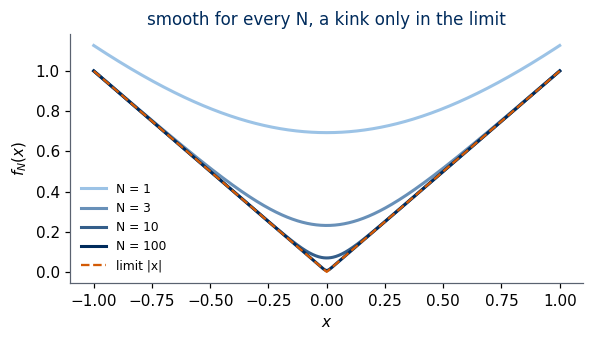

In [2]:
# a limit of smooth functions can have a kink: f_N(x) = (1/N) ln(e^{Nx} + e^{-Nx}) -> |x|
x = np.linspace(-1, 1, 801)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for i, Nx in enumerate([1, 3, 10, 100]):
    fN = np.logaddexp(Nx * x, -Nx * x) / Nx
    ax.plot(x, fN, color=blues(i / 3), lw=2, label=f"N = {Nx}")
    print(f"N = {Nx:3d}: max |f_N(x) - |x|| = {np.max(np.abs(fN - np.abs(x))):.5f}   (bound ln2/N = {np.log(2)/Nx:.5f})")
ax.plot(x, np.abs(x), color=DSOrange, ls="--", lw=1.5, label="limit |x|")
ax.set_xlabel("$x$"); ax.set_ylabel("$f_N(x)$"); ax.legend(frameon=False, fontsize=8)
ax.set_title("smooth for every N, a kink only in the limit")
plt.tight_layout(); plt.show()

### 1.1 Brute force on a tiny lattice
On an $L\times L$ torus there are $2^{L^2}$ configurations. For $L = 4$ that is $65\,536$ — easy. We store every configuration as a row of $\pm1$:
the bits of the integer $n\in\{0,\dots,2^N-1\}$ give the spins, $s = 1-2\,\text{bit}$.

**Counting broken bonds.** A bond $\langle i,j\rangle$ is *satisfied* if $s_is_j=+1$ (energy $-1$) and *broken* if $s_is_j=-1$ (energy $+1$).
With $b$ broken bonds out of $2N$, the energy is $E = -(2N-b) + b = -2N + 2b$. So $E$ depends only on $b$, and $Z$ is fixed by the histogram
$n_b$ = number of configurations with $b$ broken bonds (the *density of states*):
$$
Z(T) = \sum_{b=0}^{2N} n_b\, e^{-(-2N+2b)/T}.
$$
Every configuration and its global flip $\mathbf s\to-\mathbf s$ have the same $b$, so every $n_b$ is even. On the square-lattice torus $b$ is also always even:
the product of $s_is_j$ over all $2N$ bonds is $\prod_i s_i^4=1$, so the number of factors equal to $-1$ is even.

In [3]:
def all_configs(n):
    # all 2^n configurations of n spins, as rows of +-1 (bit k of the row index -> spin k)
    bits = (np.arange(2**n)[:, None] >> np.arange(n)) & 1
    return (1 - 2 * bits).astype(np.int8)

def torus_energies(L):
    # energies of all 2^(L*L) configurations of the L x L periodic square lattice (J = 1)
    S = all_configs(L * L).reshape(-1, L, L).astype(np.int32)
    return -(S * np.roll(S, 1, axis=1)).sum(axis=(1, 2)) - (S * np.roll(S, 1, axis=2)).sum(axis=(1, 2))

dos = {}
for L in (3, 4):
    t0 = time.perf_counter()
    E = torus_energies(L)
    N = L * L
    b = (E + 2 * N) // 2                         # number of broken bonds
    dos[L] = np.bincount(b, minlength=2 * N + 1)  # n_b
    print(f"L = {L}: {2**N:6d} configurations enumerated in {time.perf_counter()-t0:.2f} s,  sum n_b = {dos[L].sum()}")
print("4x4 torus, number of configurations with b broken bonds:")
print({int(k): int(v) for k, v in enumerate(dos[4]) if v})

L = 3:    512 configurations enumerated in 0.00 s,  sum n_b = 512
L = 4:  65536 configurations enumerated in 0.06 s,  sum n_b = 65536
4x4 torus, number of configurations with b broken bonds:
{0: 2, 4: 32, 6: 64, 8: 424, 10: 1728, 12: 6688, 14: 13568, 16: 20524, 18: 13568, 20: 6688, 22: 1728, 24: 424, 26: 64, 28: 32, 32: 2}


### 1.2 Thermodynamics of the finite lattice
With $n_b$ in hand, $\ln Z$, $u$ and $c$ follow from the formulas above, with the energy levels $E_b=-2N+2b$:
$$
\ln Z = \ln\sum_b n_b e^{-E_b/T},\qquad u = \frac{1}{N}\frac{\sum_b n_b E_b e^{-E_b/T}}{Z},\qquad c = \frac{\langle E^2\rangle - \langle E\rangle^2}{NT^2}.
$$
The function `thermo_from_dos` evaluates these sums; to avoid overflow of $e^{-E_b/T}$ it subtracts the largest exponent before exponentiating
(the "log-sum-exp" trick). The next cell plots $f$ and $c$; the cell after it checks the fluctuation formula for $c$ against a numerical derivative $du/dT$.

L = 3: specific-heat maximum c = 0.653 at T = 2.474
L = 4: specific-heat maximum c = 0.816 at T = 2.440


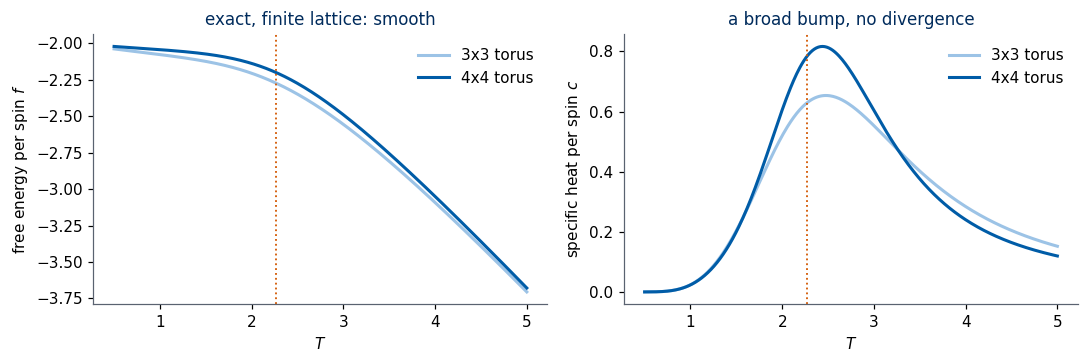

In [4]:
def thermo_from_dos(nb, N, T):
    # ln Z / N, u and c per spin from the histogram n_b of broken bonds
    T = np.atleast_1d(T)[:, None]
    Eb = -2 * N + 2 * np.arange(len(nb))
    logw = np.log(np.where(nb > 0, nb, 1)) - Eb / T
    logw = np.where(nb > 0, logw, -np.inf)
    shift = logw.max(axis=1, keepdims=True)                  # avoid overflow
    w = np.exp(logw - shift); Zr = w.sum(axis=1, keepdims=True); p = w / Zr
    E1 = (p * Eb).sum(1); E2 = (p * Eb**2).sum(1)
    lnZ = (np.log(Zr) + shift)[:, 0]
    return lnZ / N, E1 / N, (E2 - E1**2) / (N * T[:, 0]**2)

T = np.linspace(0.5, 5.0, 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for L, col in [(3, "#9CC3E6"), (4, UJBlue)]:
    lnz, u, c = thermo_from_dos(dos[L], L * L, T)
    ax[0].plot(T, -T * lnz, color=col, lw=2, label=f"{L}x{L} torus")
    ax[1].plot(T, c, color=col, lw=2, label=f"{L}x{L} torus")
    print(f"L = {L}: specific-heat maximum c = {c.max():.3f} at T = {T[c.argmax()]:.3f}")
for a in ax:
    a.axvline(TC, color=DSOrange, ls=":", lw=1.2); a.set_xlabel("$T$"); a.legend(frameon=False)
ax[0].set_ylabel("free energy per spin $f$"); ax[1].set_ylabel("specific heat per spin $c$")
ax[0].set_title("exact, finite lattice: smooth"); ax[1].set_title("a broad bump, no divergence")
plt.tight_layout(); plt.show()

In [5]:
# check: c from the energy variance equals the numerical derivative du/dT (4x4 torus)
T_chk, h_T = np.array([1.5, 2.0, 2.5, 3.0]), 1e-5
_, u_plus, _ = thermo_from_dos(dos[4], 16, T_chk + h_T)
_, u_minus, _ = thermo_from_dos(dos[4], 16, T_chk - h_T)
_, _, c_var = thermo_from_dos(dos[4], 16, T_chk)
for Tv, a, b_ in zip(T_chk, c_var, (u_plus - u_minus) / (2 * h_T)):
    print(f"T = {Tv:.1f}:  c = Var(E)/(N T^2) = {a:.8f}   c = du/dT (central difference) = {b_:.8f}")

T = 1.5:  c = Var(E)/(N T^2) = 0.20034987   c = du/dT (central difference) = 0.20034987
T = 2.0:  c = Var(E)/(N T^2) = 0.60553266   c = du/dT (central difference) = 0.60553266
T = 2.5:  c = Var(E)/(N T^2) = 0.81251523   c = du/dT (central difference) = 0.81251523
T = 3.0:  c = Var(E)/(N T^2) = 0.60313471   c = du/dT (central difference) = 0.60313471


**What we learned.** $f$ is smooth, and $c$ has a broad bump instead of a singularity — exactly as the analyticity argument demands for finite $N$.
The bump of the $4\times4$ torus lies near, but not at, $T_c$ (dotted line). Brute force cannot go much further: $L = 6$ already has
$2^{36}\approx 6.9\times10^{10}$ configurations, and the $20\times20$ images of Lab 010 have $2^{400}\approx2.6\times10^{120}$.
We need a way to perform the sum without listing the configurations. That is the **transfer matrix**, introduced first for the 1D chain, where everything can be done by hand.

<hr/>
## 2. The 1D chain and the transfer matrix

The 1D chain is the simplest place to learn the transfer-matrix method that Onsager used in 2D, and it gives a reference point: we will see that the chain has
*no* phase transition, which is what makes the 2D result remarkable.

**Setting.** $N$ spins on a ring, $s_{N+1}\equiv s_1$, with coupling $J=1$ and field $h$:
$$
H = -\sum_{i=1}^N s_is_{i+1} - h\sum_{i=1}^N s_i ,\qquad K = \beta,\quad \tilde h = \beta h .
$$

**Step 1 — the weight as a product of bond factors.** Every site belongs to two bonds, so we can give half of its field term to each:
$$
-\beta H = \sum_{i=1}^N\Big[Ks_is_{i+1} + \tfrac{\tilde h}{2}(s_i+s_{i+1})\Big]
\quad\Rightarrow\quad
e^{-\beta H} = \prod_{i=1}^N \mathsf T_{s_is_{i+1}},\qquad
\mathsf T_{ss'} = e^{Kss' + \frac{\tilde h}{2}(s+s')} .
$$
$\mathsf T_{ss'}$ is the Boltzmann weight of one bond. Labelling the rows and columns by $s=+1$ (first) and $s=-1$ (second),
$$
\mathsf T = \begin{pmatrix} e^{K+\tilde h} & e^{-K}\\ e^{-K} & e^{K-\tilde h}\end{pmatrix}.
$$

**Step 2 — the sum over spins is matrix multiplication.** The spin $s_2$ appears only in $\mathsf T_{s_1s_2}\mathsf T_{s_2s_3}$, and
$\sum_{s_2}\mathsf T_{s_1s_2}\mathsf T_{s_2s_3} = (\mathsf T^2)_{s_1s_3}$ is the definition of the matrix product. Summing $s_2,\dots,s_N$ in turn and closing the ring:
$$
Z = \sum_{s_1,\dots,s_N}\mathsf T_{s_1s_2}\mathsf T_{s_2s_3}\cdots\mathsf T_{s_Ns_1} = \sum_{s_1}(\mathsf T^N)_{s_1s_1} = \operatorname{Tr}\mathsf T^N .
$$
A sum of $2^N$ terms has become $N-1$ multiplications of $2\times2$ matrices.

**Step 3 — eigenvalues.** $\mathsf T$ is real symmetric, so $\mathsf T = U\Lambda U^\top$ with $U$ orthogonal and $\Lambda=\operatorname{diag}(\lambda_+,\lambda_-)$.
Then $\mathsf T^N = U\Lambda^NU^\top$ and, since the trace is invariant under $U$,
$$
Z = \lambda_+^N + \lambda_-^N .
$$
The eigenvalues of a symmetric $2\times2$ matrix $\begin{pmatrix}a&b\\b&d\end{pmatrix}$ are $\frac{a+d}{2}\pm\sqrt{\left(\frac{a-d}{2}\right)^2+b^2}$, so
$$
\lambda_\pm = e^{K}\cosh\tilde h \pm \sqrt{e^{2K}\sinh^2\tilde h + e^{-2K}},\qquad \text{at } h=0:\ \lambda_\pm = e^K\pm e^{-K},\ \text{i.e. } \lambda_+ = 2\cosh K,\ \lambda_- = 2\sinh K ,
$$
with eigenvectors $(1,1)/\sqrt2$ and $(1,-1)/\sqrt2$ at $h=0$.

*Example ($N=2$, $h=0$).* A ring of two spins has two bonds between the same pair, so directly $Z=\sum_{s_1,s_2}e^{2Ks_1s_2} = 2e^{2K}+2e^{-2K}=4\cosh2K$.
The formula gives $(2\cosh K)^2+(2\sinh K)^2 = 4(\cosh^2K+\sinh^2K) = 4\cosh 2K$, the same.

The cell below checks $\operatorname{Tr}\mathsf T^N$ against brute force for $N=14$ and the closed form of $\lambda_\pm$ against `numpy`.

**The same derivation in SymPy.** We let the computer-algebra system SymPy diagonalise $\mathsf T$ symbolically, confirm the closed form of $\lambda_\pm$
(by comparing the radicands), the values at $h=0$, and the $N=2$ example. The numerical check against brute force follows in the next cell.

In [6]:
K, ht = sp.symbols("K htilde", positive=True)
T_sym = sp.Matrix([[sp.exp(K + ht), sp.exp(-K)], [sp.exp(-K), sp.exp(K - ht)]])
display(sp.Eq(sp.Symbol(r"\mathsf{T}"), T_sym, evaluate=False))
a, b_, d = T_sym[0, 0], T_sym[0, 1], T_sym[1, 1]
radicand_matrix = ((a - d) / 2)**2 + b_**2                                   # eigenvalues: (a+d)/2 +- sqrt(radicand)
radicand_formula = sp.exp(2 * K) * sp.sinh(ht)**2 + sp.exp(-2 * K)
print("(a+d)/2 - e^K cosh(h~)                      =", sp.simplify(((a + d) / 2 - sp.exp(K) * sp.cosh(ht)).rewrite(sp.exp)))
print("radicand - (e^{2K} sinh^2 h~ + e^{-2K})      =", sp.simplify((radicand_matrix - radicand_formula).rewrite(sp.exp)))
lam_h0 = [sp.simplify(sp.Rational(1, 2) * (2 * sp.exp(K)) + s * sp.sqrt(sp.exp(-2 * K))) for s in (1, -1)]
print("lambda_+ - 2 cosh K at h = 0                 =", sp.simplify((lam_h0[0] - 2 * sp.cosh(K)).rewrite(sp.exp)))
print("lambda_- - 2 sinh K at h = 0                 =", sp.simplify((lam_h0[1] - 2 * sp.sinh(K)).rewrite(sp.exp)))
print("eigenvalues of T(h=0) from SymPy             :", [sp.simplify(e.rewrite(sp.cosh)) for e in T_sym.subs(ht, 0).eigenvals()])
print("N = 2 example: Tr T^2 - 4 cosh 2K            =", sp.simplify(((T_sym.subs(ht, 0)**2).trace() - 4 * sp.cosh(2 * K)).rewrite(sp.exp)))

Eq(\mathsf{T}, Matrix([
[exp(K + htilde),         exp(-K)],
[        exp(-K), exp(K - htilde)]]))

(a+d)/2 - e^K cosh(h~)                      = 0
radicand - (e^{2K} sinh^2 h~ + e^{-2K})      = 0
lambda_+ - 2 cosh K at h = 0                 = 0
lambda_- - 2 sinh K at h = 0                 = 0
eigenvalues of T(h=0) from SymPy             : [2*cosh(K), 2*sinh(K)]
N = 2 example: Tr T^2 - 4 cosh 2K            = 0


In [7]:
def Z_chain_brute(N, K, ht):
    S = all_configs(N).astype(float)
    E_over_T = -K * (S * np.roll(S, -1, axis=1)).sum(1) - ht * S.sum(1)     # beta*H
    return np.exp(-E_over_T).sum()

def T_chain(K, ht):
    return np.array([[np.exp(K + ht), np.exp(-K)], [np.exp(-K), np.exp(K - ht)]])

N = 14
for K, ht in [(0.3, 0.0), (1.0, 0.0), (0.7, 0.4), (1.5, -0.2)]:
    Zb = Z_chain_brute(N, K, ht)
    Zt = np.trace(np.linalg.matrix_power(T_chain(K, ht), N))
    lam_num = np.sort(np.linalg.eigvalsh(T_chain(K, ht)))[::-1]
    root = np.sqrt(np.exp(2 * K) * np.sinh(ht)**2 + np.exp(-2 * K))
    lam_exact = np.array([np.exp(K) * np.cosh(ht) + root, np.exp(K) * np.cosh(ht) - root])
    print(f"K={K:3.1f}, beta*h={ht:4.1f}:  Z brute = {Zb:.10e}   Tr T^N = {Zt:.10e}   "
          f"max|lambda_numpy - lambda_formula| = {np.abs(lam_num - lam_exact).max():.1e}")

K=0.3, beta*h= 0.0:  Z brute = 3.0480162419e+04   Tr T^N = 3.0480162419e+04   max|lambda_numpy - lambda_formula| = 1.1e-16


K=1.0, beta*h= 0.0:  Z brute = 7.2668862529e+06   Tr T^N = 7.2668862529e+06   max|lambda_numpy - lambda_formula| = 0.0e+00
K=0.7, beta*h= 0.4:  Z brute = 9.1298799858e+06   Tr T^N = 9.1298799858e+06   max|lambda_numpy - lambda_formula| = 8.9e-16
K=1.5, beta*h=-0.2:  Z brute = 2.3316896955e+10   Tr T^N = 2.3316896955e+10   max|lambda_numpy - lambda_formula| = 4.4e-16


### 2.1 Free energy and correlation length of the chain

**Free energy.** Factor out the larger eigenvalue: $\ln Z = N\ln\lambda_+ + \ln\big(1 + r^N\big)$ with $r=\lambda_-/\lambda_+ = \tanh K<1$.
The second term tends to $0$, so for $N\to\infty$ only the largest eigenvalue survives:
$$
-\beta f = \ln\lambda_+ = \ln\big(2\cosh K\big),\qquad u = \frac{\partial(\beta f)}{\partial\beta} = -\tanh K,\qquad c = \frac{\partial u}{\partial T} = \frac{K^2}{\cosh^2K}.
$$
These are compositions of analytic functions with $2\cosh K>0$: $f$ is analytic at every $T>0$, so **the 1D chain has no phase transition** [Ising 1925].
The specific heat is a single smooth bump that does not depend on $N$.

**Correlation function.** How strongly does spin $s_0$ influence spin $s_r$? The product $s_0s_r$ inserts the diagonal matrix
$\sigma^z = \operatorname{diag}(1,-1)$ at the two positions:
$$
\langle s_0s_r\rangle = \frac{\operatorname{Tr}\big(\sigma^z\mathsf T^r\sigma^z\mathsf T^{N-r}\big)}{\operatorname{Tr}\mathsf T^N}.
$$
Write $\mathsf T = \lambda_+|{+}\rangle\langle{+}| + \lambda_-|{-}\rangle\langle{-}|$ with the eigenvectors $|{\pm}\rangle = (1,\pm1)/\sqrt2$.
For $N\to\infty$, $\mathsf T^{N-r}\approx\lambda_+^{N-r}|{+}\rangle\langle{+}|$, and $\sigma^z$ maps $|{+}\rangle$ to $|{-}\rangle$. Hence
$$
\langle s_0s_r\rangle \to \frac{\lambda_+^{N-r}\,\langle{-}|\mathsf T^r|{-}\rangle}{\lambda_+^N} = \Big(\frac{\lambda_-}{\lambda_+}\Big)^r = (\tanh K)^r = e^{-r/\xi},\qquad
\xi = \frac{1}{\ln(\lambda_+/\lambda_-)} = -\frac{1}{\ln\tanh K}.
$$
$\xi$ is the **correlation length**: the distance over which a spin "remembers" the orientation of another. It is finite at every $T>0$.

**A second way to see it.** At $h=0$ the bond variables $\tau_i = s_is_{i+1}$ of an open chain are independent: each bond is broken ($\tau_i=-1$) with probability
$p = e^{-K}/(e^K+e^{-K})$. Since $s_0s_r = \tau_0\tau_1\cdots\tau_{r-1}$, $\ \langle s_0s_r\rangle = \langle\tau\rangle^r = (1-2p)^r = (\tanh K)^r$.
Each broken bond (a *domain wall*) flips the sign of the correlation. At low $T$, $p\approx e^{-2K}$ and $\xi\approx \frac12e^{2K}$:
the walls are rare but never absent, and $\xi$ diverges only at $T=0$.

In [8]:
# SymPy: f, u, c and the eigenvalue ratio of the infinite chain (h = 0)
K, Tt = sp.symbols("K T", positive=True)
minus_beta_f = sp.log(2 * sp.cosh(K))
u_sym = -sp.diff(minus_beta_f, K)                              # u = d(beta f)/d beta, beta = K for J = 1
c_sym = sp.simplify(sp.diff(u_sym.subs(K, 1 / Tt), Tt).subs(Tt, 1 / K))
display(sp.Eq(sp.Symbol("u"), sp.simplify(u_sym)), sp.Eq(sp.Symbol("c"), c_sym),
        sp.Eq(sp.Symbol(r"\lambda_-/\lambda_+"), sp.simplify(sp.sinh(K) / sp.cosh(K))))
# numerical check: u from a finite difference of ln(lambda_+) of the numerical matrix
for Kv in (0.5, 1.0, 2.0):
    lnlam = lambda k: np.log(np.max(np.linalg.eigvalsh(T_chain(k, 0.0))))
    u_fd = -(lnlam(Kv + 1e-6) - lnlam(Kv - 1e-6)) / 2e-6
    print(f"K = {Kv}: u (finite difference of ln lambda_max) = {u_fd:.8f},  -tanh K = {-np.tanh(Kv):.8f}")

Eq(u, -tanh(K))

Eq(c, K**2/cosh(K)**2)

Eq(\lambda_-/\lambda_+, tanh(K))

K = 0.5: u (finite difference of ln lambda_max) = -0.46211716,  -tanh K = -0.46211716
K = 1.0: u (finite difference of ln lambda_max) = -0.76159416,  -tanh K = -0.76159416
K = 2.0: u (finite difference of ln lambda_max) = -0.96402758,  -tanh K = -0.96402758


K = 0.5: max |<s0 sr> - tanh(K)^r| over r<25 = 7.1e-17,  xi = 1.295
K = 1.0: max |<s0 sr> - tanh(K)^r| over r<25 = 1.1e-16,  xi = 3.672
K = 1.5: max |<s0 sr> - tanh(K)^r| over r<25 = 4.4e-16,  xi = 10.034


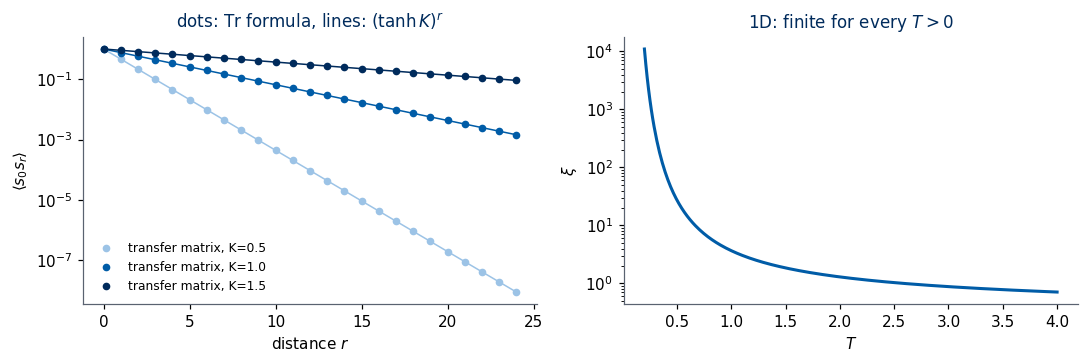

In [9]:
sz = np.diag([1.0, -1.0])
N, r = 400, np.arange(0, 25)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for K, col in [(0.5, "#9CC3E6"), (1.0, UJBlue), (1.5, UJNavy)]:
    Tm = T_chain(K, 0.0) / (2 * np.cosh(K))                 # rescaled, to avoid overflow; ratios are unchanged
    corr = [np.trace(sz @ np.linalg.matrix_power(Tm, k) @ sz @ np.linalg.matrix_power(Tm, N - k)) /
            np.trace(np.linalg.matrix_power(Tm, N)) for k in r]
    ax[0].semilogy(r, corr, "o", color=col, ms=4, label=f"transfer matrix, K={K}")
    ax[0].semilogy(r, np.tanh(K)**r, "-", color=col, lw=1)
    print(f"K = {K}: max |<s0 sr> - tanh(K)^r| over r<25 = {np.max(np.abs(np.array(corr) - np.tanh(K)**r)):.1e},"
          f"  xi = {-1/np.log(np.tanh(K)):.3f}")
ax[0].set_xlabel("distance $r$"); ax[0].set_ylabel(r"$\langle s_0 s_r\rangle$"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title(r"dots: $\mathrm{Tr}$ formula, lines: $(\tanh K)^r$")
Tg = np.linspace(0.2, 4, 300)
ax[1].plot(Tg, -1 / np.log(np.tanh(1 / Tg)), color=UJBlue, lw=2)
ax[1].set_yscale("log"); ax[1].set_xlabel("$T$"); ax[1].set_ylabel(r"$\xi$"); ax[1].set_title("1D: finite for every $T>0$")
plt.tight_layout(); plt.show()

In [10]:
# the 1D chain: specific heat bump, broken-bond probability and the low-T form of xi
Kv = np.linspace(0.05, 10, 200001)
c1d = Kv**2 / np.cosh(Kv)**2
print(f"1D specific heat c = K^2/cosh^2 K: maximum {c1d.max():.4f} at T = {1/Kv[c1d.argmax()]:.4f} (independent of N)")
for K in (0.5, 1.0, 2.0, 3.0, 4.0):
    p_br = np.exp(-K) / (2 * np.cosh(K))
    xi1 = -1 / np.log(np.tanh(K))
    print(f"K = {K}:  1 - 2p = {1 - 2*p_br:.10f}, tanh K = {np.tanh(K):.10f};   xi = {xi1:10.4f},  e^(2K)/2 = {np.exp(2*K)/2:10.4f}")

1D specific heat c = K^2/cosh^2 K: maximum 0.4392 at T = 0.8336 (independent of N)
K = 0.5:  1 - 2p = 0.4621171573, tanh K = 0.4621171573;   xi =     1.2954,  e^(2K)/2 =     1.3591
K = 1.0:  1 - 2p = 0.7615941560, tanh K = 0.7615941560;   xi =     3.6719,  e^(2K)/2 =     3.6945
K = 2.0:  1 - 2p = 0.9640275801, tanh K = 0.9640275801;   xi =    27.2960,  e^(2K)/2 =    27.2991
K = 3.0:  1 - 2p = 0.9950547537, tanh K = 0.9950547537;   xi =   201.7140,  e^(2K)/2 =   201.7144
K = 4.0:  1 - 2p = 0.9993292997, tanh K = 0.9993292997;   xi =  1490.4789,  e^(2K)/2 =  1490.4790


**What we learned.** For $N\to\infty$ only the largest eigenvalue matters, $\ln Z \approx N\ln\lambda_{\max}$, and the correlation length is set by the ratio
of the two largest eigenvalues, $\xi = 1/\ln(\lambda_{\max}/\lambda_2)$. Both statements carry over to 2D unchanged; what changes is the size of the matrix.
A phase transition would require $\lambda_2/\lambda_{\max}\to1$ (so that $\xi\to\infty$) at some $T>0$, which a $2\times2$ matrix with positive entries never allows:
by the Perron–Frobenius theorem its largest eigenvalue is strictly larger than the other in absolute value.

<hr/>
## 3. Two dimensions: a transfer matrix of size $2^L\times2^L$

The 1D method extends to 2D if a whole *column* of spins plays the role of a single spin. The price is the size of the matrix, $2^L\times2^L$.
For small widths $L$ we can diagonalise it numerically; this gives exact results for infinitely long strips, shows how a transition builds up as $L$ grows,
and sets the stage for Onsager, who found the largest eigenvalue for every $L$ analytically.

**Setting.** A strip of $L$ rows (periodic in the vertical direction, $s_{L+1}\equiv s_1$) and $L'$ columns (periodic, $L'\to\infty$ at the end).
A column $\sigma = (s_1,\dots,s_L)$ has $2^L$ states. The energy splits into bonds *inside* a column (vertical) and bonds *between* neighbouring columns (horizontal):
$$
-\beta H = \sum_{j=1}^{L'}\Big[K\sum_{i=1}^L s_i^{(j)}s_i^{(j+1)} + K\sum_{i=1}^L s_i^{(j)}s_{i+1}^{(j)}\Big],
$$
where $s_i^{(j)}$ is the spin in row $i$ of column $j$. Give half of each column's internal energy to the factor on its left and half to the one on its right:
$$
Z = \sum_{\sigma_1,\dots,\sigma_{L'}}\mathsf V_{\sigma_1\sigma_2}\mathsf V_{\sigma_2\sigma_3}\cdots\mathsf V_{\sigma_{L'}\sigma_1} = \operatorname{Tr}\mathsf V^{L'},\qquad
\mathsf V_{\sigma\sigma'} = \exp\Big[K\sum_{i=1}^L s_is_i' + \frac K2\sum_{i=1}^L\big(s_is_{i+1} + s'_is'_{i+1}\big)\Big].
$$
**Meaning of an element.** $\mathsf V_{\sigma\sigma'}$ is the Boltzmann weight of placing column $\sigma'$ to the right of column $\sigma$: the $L$ horizontal bonds
between them, and half of the vertical bonds of each. The half–half split makes $\mathsf V$ symmetric, $\mathsf V_{\sigma\sigma'}=\mathsf V_{\sigma'\sigma}$.

*Example ($L=2$).* Two rows on a periodic column are joined by two vertical bonds, so $\sum_is_is_{i+1}=2s_1s_2$. For $\sigma=\sigma'=(+,+)$:
$\mathsf V = \exp[2K + \tfrac K2(2+2)] = e^{4K}$. For $\sigma=(+,+)$, $\sigma'=(-,-)$: $\mathsf V = \exp[-2K + 2K] = 1$. The code checks both.

**Free energy and correlation length of the strip.** As in 1D, $Z=\sum_k\lambda_k^{L'}$ over the eigenvalues of $\mathsf V$. All entries of $\mathsf V$ are positive,
so by the Perron–Frobenius theorem the largest eigenvalue $\lambda_0$ is positive, non-degenerate, and strictly larger than all others in absolute value.
For $L'\to\infty$, $\ln Z \approx L'\ln\lambda_0$, and dividing by the number of spins $LL'$:
$$
f_L(T) = -\frac{T}{L}\ln\lambda_0(L),\qquad \xi_L = \frac{1}{\ln(\lambda_0/\lambda_1)},
$$
where $\xi_L$ is the correlation length along the strip and $\lambda_1$ is the largest eigenvalue that couples to a single spin (defined precisely below).
Onsager's free energy is $f = \lim_{L\to\infty}f_L$. The cost: $\mathsf V$ has $4^L$ entries — $L=12$ needs $1.7\times10^7$ numbers, $L=50$ would need $10^{30}$.

**Symmetry sectors.** Flipping all spins, $\sigma\to-\sigma$, does not change $\mathsf V$. In our bit encoding the flip maps the index $n\to \bar n = 2^L-1-n$.
Vectors with $v_{\bar n}=v_n$ (even) and $v_{\bar n}=-v_n$ (odd) are mapped by $\mathsf V$ into vectors of the same type, so $\mathsf V$ splits into an even block
($\mathsf V_{nm}+\mathsf V_{n\bar m}$) and an odd block ($\mathsf V_{nm}-\mathsf V_{n\bar m}$), each of size $2^{L-1}$, with $n,m<2^{L-1}$.
$\lambda_0$ (positive eigenvector) is the top of the even block. A single spin $s_i$ changes sign under the flip, so it connects the even sector to the odd one, and
the correlation $\langle s_i^{(0)}s_i^{(r)}\rangle$ decays as $(\lambda_1/\lambda_0)^r$ with $\lambda_1$ the top of the odd block — exactly as $\lambda_-$ in 1D.

**Check first:** on an $L\times L'$ torus, $Z = \operatorname{Tr}\mathsf V^{L'}$ exactly — we compare with the brute-force histogram of Section 1 for $4\times4$.

In [11]:
def transfer_matrix(L, K, lattice="square"):
    # V[sigma, sigma'] for a periodic column of L spins; 'triangular' adds the diagonal bonds s_i s'_{i+1} (Section 10)
    S = all_configs(L).astype(float)
    intra = (S * np.roll(S, -1, axis=1)).sum(1)                 # sum_i s_i s_{i+1} inside a column
    inter = S @ S.T                                             # sum_i s_i s'_i
    if lattice == "triangular":
        inter = inter + S @ np.roll(S, -1, axis=1).T            # sum_i s_i s'_{i+1}
    return np.exp(K * (inter + 0.5 * (intra[:, None] + intra[None, :])))

def top_eigenvalue(A, symmetric):
    n = A.shape[0]
    if symmetric and n <= 64:
        return eigh(A, eigvals_only=True, subset_by_index=[n - 1, n - 1])[0]
    if symmetric:
        return eigsh(A, k=1, which="LA", tol=0)[0][0]           # Lanczos: only the top eigenvalue
    if n <= 64:
        return np.max(np.linalg.eigvals(A).real)
    return eigs(A, k=1, which="LR", tol=1e-14)[0][0].real

def lambda01(L, K, lattice="square"):
    # (lambda_0, lambda_1): largest eigenvalues in the spin-flip even and odd sectors
    V = transfer_matrix(L, K, lattice)
    n = V.shape[0] // 2
    Vflip = V[:, ::-1]                                          # column m -> its flipped partner 2^L-1-m
    sym = lattice == "square"
    return (top_eigenvalue(V[:n, :n] + Vflip[:n, :n], sym),
            top_eigenvalue(V[:n, :n] - Vflip[:n, :n], sym))

# check: Z of the 4x4 torus from Tr V^4 versus the brute-force histogram
for T in (1.5, TC, 3.5):
    V = transfer_matrix(4, 1 / T)
    Z_tm = np.trace(np.linalg.matrix_power(V, 4))
    lnz_dos, _, _ = thermo_from_dos(dos[4], 16, T)
    print(f"T = {T:.4f}:  ln Z (Tr V^4) = {np.log(Z_tm):.12f}   ln Z (brute force) = {16 * lnz_dos[0]:.12f}")

T = 1.5000:  ln Z (Tr V^4) = 22.117013911716   ln Z (brute force) = 22.117013911716
T = 2.2692:  ln Z (Tr V^4) = 15.521915458755   ln Z (brute force) = 15.521915458755
T = 3.5000:  ln Z (Tr V^4) = 12.600438025330   ln Z (brute force) = 12.600438025330


In [12]:
# example L = 2: index 0 = (+,+), index 3 = (-,-)
K = 0.3
V2 = transfer_matrix(2, K)
print(f"V[(+,+),(+,+)] = {V2[0, 0]:.10f}   e^(4K) = {np.exp(4*K):.10f}")
print(f"V[(+,+),(-,-)] = {V2[0, 3]:.10f}   expected 1")
print(f"V symmetric: max |V - V^T| = {np.abs(V2 - V2.T).max():.1e}")

V[(+,+),(+,+)] = 3.3201169227   e^(4K) = 3.3201169227
V[(+,+),(-,-)] = 1.0000000000   expected 1
V symmetric: max |V - V^T| = 0.0e+00


### 3.1 Free energy and specific heat of strips, $L = 4,\dots,10$
We now scan temperature for strips of width $L=4,6,8,10$. The specific heat $c_L = -T\,\partial^2 f_L/\partial T^2$ (from $u=\partial(\beta f)/\partial\beta$ and
$c=\partial u/\partial T$) is computed by finite differences on a fine grid; the eigenvalues are accurate to machine precision, so the second difference is reliable.
Onsager's $f$ (Section 6) is plotted for comparison. Three things to look for: how fast $f_L$ approaches $f$, how the specific-heat peak changes with $L$,
and how $\xi_L/L$ behaves.

strip transfer matrices: 8.2 s


L =  4:  c_max = 0.8728 at T = 2.210;   |f_L - f| at T = 1.5, T_c, 3.5:  3.5e-03, 3.9e-02, 1.1e-02
L =  6:  c_max = 1.0739 at T = 2.240;   |f_L - f| at T = 1.5, T_c, 3.5:  3.7e-04, 1.7e-02, 1.3e-03
L =  8:  c_max = 1.2160 at T = 2.250;   |f_L - f| at T = 1.5, T_c, 3.5:  4.8e-05, 9.4e-03, 2.1e-04
L = 10:  c_max = 1.3262 at T = 2.260;   |f_L - f| at T = 1.5, T_c, 3.5:  6.8e-06, 6.0e-03, 3.5e-05


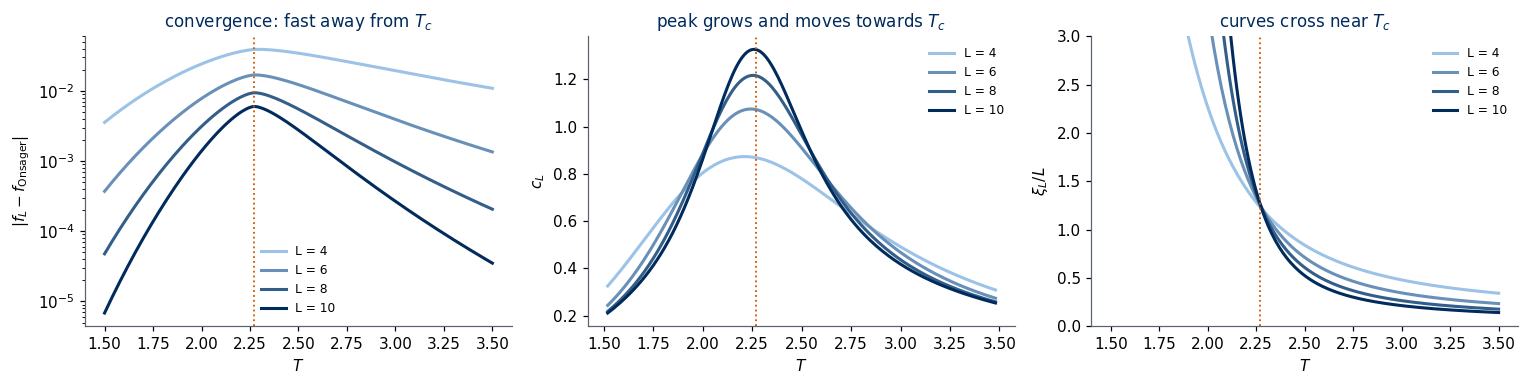

In [13]:
def f_onsager(T):
    # Onsager 1944: -beta f = ln(2 cosh 2K) + (1/2pi) int_0^pi ln[(1 + sqrt(1 - kappa^2 sin^2 phi))/2] dphi
    K = 1.0 / T
    k = 2 * np.sinh(2 * K) / np.cosh(2 * K)**2
    g = lambda p: np.log(0.5 * (1 + np.sqrt(max(0.0, 1 - k**2 * np.sin(p)**2))))
    with warnings.catch_warnings():                 # at T = T_c the integrand has a kink; quad warns but the result is accurate
        warnings.simplefilter("ignore", IntegrationWarning)
        I, _ = quad(g, 0, np.pi, points=[np.pi / 2], limit=200, epsabs=1e-13, epsrel=1e-13)
    return -T * (np.log(2 * np.cosh(2 * K)) + I / (2 * np.pi))

Ls = [4, 6, 8, 10]
Tgrid = np.linspace(1.5, 3.5, 201); dT = Tgrid[1] - Tgrid[0]
strip = {}
t0 = time.perf_counter()
for L in Ls:
    lam = np.array([lambda01(L, 1 / T) for T in Tgrid])
    fL = -Tgrid * np.log(lam[:, 0]) / L
    cL = -Tgrid * np.gradient(np.gradient(fL, dT), dT)
    xiL = 1 / np.log(lam[:, 0] / lam[:, 1])
    strip[L] = dict(f=fL, c=cL, xi=xiL)
print(f"strip transfer matrices: {time.perf_counter() - t0:.1f} s")
f_inf = np.array([f_onsager(T) for T in Tgrid])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for i, L in enumerate(Ls):
    col = blues(i / (len(Ls) - 1))
    ax[0].semilogy(Tgrid, np.abs(strip[L]["f"] - f_inf), color=col, lw=2, label=f"L = {L}")
    s = slice(2, -2)                                                   # drop the one-sided ends of np.gradient
    ax[1].plot(Tgrid[s], strip[L]["c"][s], color=col, lw=2, label=f"L = {L}")
    k = np.argmax(strip[L]["c"][s])
    print(f"L = {L:2d}:  c_max = {strip[L]['c'][s][k]:.4f} at T = {Tgrid[s][k]:.3f};   "
          f"|f_L - f| at T = 1.5, T_c, 3.5:  {abs(strip[L]['f'][0]-f_inf[0]):.1e}, "
          f"{abs(-TC*np.log(lambda01(L, KC)[0])/L - f_onsager(TC)):.1e}, {abs(strip[L]['f'][-1]-f_inf[-1]):.1e}")
    ax[2].plot(Tgrid, strip[L]["xi"] / L, color=col, lw=2, label=f"L = {L}")
for a in ax:
    a.axvline(TC, color=DSOrange, ls=":", lw=1.2); a.set_xlabel("$T$"); a.legend(frameon=False, fontsize=8)
ax[0].set_ylabel(r"$|f_L - f_{\rm Onsager}|$"); ax[0].set_title("convergence: fast away from $T_c$")
ax[1].set_ylabel("$c_L$"); ax[1].set_title("peak grows and moves towards $T_c$")
ax[2].set_ylabel(r"$\xi_L / L$"); ax[2].set_ylim(0, 3); ax[2].set_title(r"curves cross near $T_c$")
plt.tight_layout(); plt.show()

Three observations, all visible above:

* **Away from $T_c$** $f_L$ converges to Onsager's $f$ exponentially fast in $L$: the correlation length is finite, and a strip much wider than $\xi$
  behaves like the infinite plane.
* **At $T_c$** convergence is only a power law ($\propto 1/L^2$, Section 8.1) — the strip is never wider than $\xi=\infty$. The peak of $c_L$ grows (slowly — the
  divergence will turn out to be logarithmic, Section 8) and moves towards $T_c$. This is how a singularity of the infinite system appears in finite ones.
* $\xi_L/L$ **decreases** with $L$ above $T_c$ (finite $\xi$: $\xi_L$ saturates while $L$ grows), **increases** below $T_c$ (two ordered states, all up or all down,
  become degenerate, $\lambda_1\to\lambda_0$, $\xi_L\to\infty$), and is $L$-independent exactly at $T_c$, where the only length scale is $L$ itself.
  The crossing points of the curves for $L$ and $L+2$ therefore locate $T_c$ — the same logic as the finite-size analysis of the CNN, but with an exact algorithm.

### 3.2 Locating $T_c$ from the crossings
For each pair of widths $(L, L+2)$ we solve $\xi_L(T)/L = \xi_{L+2}(T)/(L+2)$ for $T$ by root finding (`brentq`) and compare the crossing temperature $T^*(L)$ with the exact $T_c$.

In [14]:
def xi_over_L(L, T, lattice="square"):
    l0, l1 = lambda01(L, 1 / T, lattice)
    return 1 / np.log(l0 / l1) / L

print(" L, L+2   crossing T*(L)      T*(L) - T_c")
for L in (4, 6, 8, 10):
    t0 = time.perf_counter()
    Tx = brentq(lambda T: xi_over_L(L, T) - xi_over_L(L + 2, T), 2.0, 2.6, xtol=1e-12)
    print(f"{L:2d}, {L+2:2d}   {Tx:.8f}      {Tx - TC:+.2e}     ({time.perf_counter()-t0:.1f} s)")
print(f"exact T_c = {TC:.8f}")

 L, L+2   crossing T*(L)      T*(L) - T_c
 4,  6   2.28780299      +1.86e-02     (0.0 s)
 6,  8   2.27494894      +5.76e-03     (0.1 s)


 8, 10   2.27168848      +2.50e-03     (0.5 s)


10, 12   2.27050963      +1.32e-03     (13.8 s)
exact T_c = 2.26918531


The crossings approach $T_c$ quickly. With matrices of size at most $2^{12}\times2^{12}$ we get $T_c$ to several digits, without Monte Carlo noise.
For $L = 50$ the matrix would have $2^{50}\approx10^{15}$ rows: no computer can diagonalise it. Onsager's achievement was to find $\lambda_0$ **analytically** for every $L$
(Section 6).

### 3.3 One dimension against two
The strips let us see directly why 2D differs from 1D. The 1D chain has $\xi = -1/\ln\tanh K$, finite at every $T>0$; its specific heat $K^2/\cosh^2K$ is one smooth bump.
In 2D, the strip correlation lengths grow without bound below $T_c$, and above $T_c$ they converge to the exact 2D correlation length along a lattice axis,
$\xi = 1/[2(K^*-K)]$ with $K^*$ the dual coupling, $e^{-2K^*}=\tanh K$ (Sections 5 and 6.1, where this formula is derived and checked).
It diverges at $T_c$, where $K^*=K$.

**Energy against entropy.** A simple counting explains the difference.

* *1D.* Start from an open chain of $N$ spins, all up. Breaking one bond (one domain wall) costs energy $2J$, and the wall can sit at any of $N-1$ positions,
  an entropy $\ln(N-1)$. The free-energy change $\Delta F = 2J - T\ln(N-1)$ is negative once $N-1>e^{2J/T}$: at any $T>0$ a long enough chain breaks into domains,
  of typical length $\sim e^{2K}$ — in line with $\xi\approx\frac12e^{2K}$ from Section 2.1.
* *2D.* A domain of flipped spins is bounded by a closed wall. A wall of length $\ell$ (number of broken bonds) costs $2J\ell$ — proportional to its length, not constant.
  The number of closed walls of length $\ell$ through a given bond is at most the number of lattice paths of $\ell$ steps that never immediately step back,
  $\le 4\cdot3^{\ell-1}$. So the entropy is at most $\approx\ell\ln3$ and $\Delta F\gtrsim\ell\,(2J-T\ln3)$, positive for $T<2J/\ln3\approx1.82$:
  large flipped domains are suppressed and the order survives at low $T$. This is the idea of Peierls' argument [Peierls 1936; rigorous form: Griffiths 1964].
  It is consistent with $T_c\approx2.269>1.82$.

The next cell evaluates these numbers and plots $\xi$ and $c$ for 1D and 2D.

1D chain, N =      10: one domain wall lowers F (Delta F = 2 - T ln(N-1) < 0) for T > 0.9102
1D chain, N =    1000: one domain wall lowers F (Delta F = 2 - T ln(N-1) < 0) for T > 0.2896
1D chain, N = 1000000: one domain wall lowers F (Delta F = 2 - T ln(N-1) < 0) for T > 0.1448
2D: the bound Delta F >~ l (2 - T ln 3) is positive for T < 2/ln 3 = 1.8205;   exact T_c = 2.2692


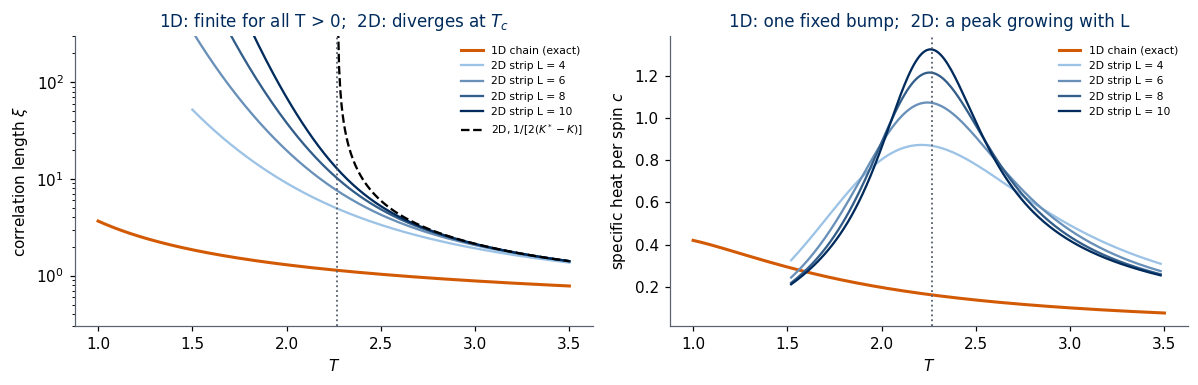

In [15]:
# 1D chain versus 2D strips: correlation length and specific heat
for Nch in (10, 10**3, 10**6):
    print(f"1D chain, N = {Nch:>7d}: one domain wall lowers F (Delta F = 2 - T ln(N-1) < 0) for T > {2/np.log(Nch-1):.4f}")
print(f"2D: the bound Delta F >~ l (2 - T ln 3) is positive for T < 2/ln 3 = {2/np.log(3):.4f};   exact T_c = {TC:.4f}")

Tq = np.linspace(1.0, 3.5, 400)
xi_1d = -1 / np.log(np.tanh(1 / Tq))
Kq = 1 / Tq; Kq_dual = -0.5 * np.log(np.tanh(Kq))
xi_2d = np.where(Tq > TC, 1 / (2 * (Kq_dual - Kq)), np.nan)        # exact, T > T_c (Section 6.1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(Tq, xi_1d, color=DSOrange, lw=2, label="1D chain (exact)")
for i, L in enumerate(Ls):
    ax[0].plot(Tgrid, strip[L]["xi"], color=blues(i / (len(Ls) - 1)), lw=1.5, label=f"2D strip L = {L}")
ax[0].plot(Tq, xi_2d, color="k", ls="--", lw=1.5, label=r"2D, $1/[2(K^*-K)]$")
ax[0].set_yscale("log"); ax[0].set_ylim(0.3, 300); ax[0].set_ylabel(r"correlation length $\xi$")
ax[0].set_title("1D: finite for all T > 0;  2D: diverges at $T_c$")
ax[1].plot(Tq, 1 / Tq**2 / np.cosh(1 / Tq)**2, color=DSOrange, lw=2, label="1D chain (exact)")
for i, L in enumerate(Ls):
    ax[1].plot(Tgrid[2:-2], strip[L]["c"][2:-2], color=blues(i / (len(Ls) - 1)), lw=1.5, label=f"2D strip L = {L}")
ax[1].set_ylabel("specific heat per spin $c$"); ax[1].set_title("1D: one fixed bump;  2D: a peak growing with L")
for a in ax:
    a.axvline(TC, color=UJGray, ls=":", lw=1.2); a.set_xlabel("$T$"); a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

<hr/>
## 4. High- and low-temperature expansions of $Z$

Before Onsager, the 2D model was studied through expansions of $Z$ that are accurate far from $T_c$: in powers of a small parameter at high $T$ and at low $T$.
Their value for us is structural: the two series turn out to count *the same* geometric objects, and this coincidence (Section 5) pins down $T_c$ exactly.

### 4.1 High temperature: closed graphs
At high $T$, $K$ is small. Since $ss'=\pm1$ and $e^{\pm K}=\cosh K\pm\sinh K$,
$$
e^{Kss'} = \cosh K + ss'\sinh K = \cosh K\,(1 + t\,ss'),\qquad t = \tanh K .
$$
Insert this for every one of the $2N$ bonds:
$$
Z = (\cosh K)^{2N}\sum_{\mathbf s}\prod_{\langle i,j\rangle}\big(1 + t\,s_is_j\big).
$$
**Expanding the product.** From each bond factor pick either $1$ or $t\,s_is_j$. A choice is a subset $G$ of bonds (those where $t\,s_is_j$ was picked); it contributes
$t^{|G|}\prod_{\langle i,j\rangle\in G}s_is_j = t^{|G|}\prod_i s_i^{d_i(G)}$, where $d_i(G)$ is the number of bonds of $G$ touching site $i$.
**Summing over spins.** $\sum_{s=\pm1}s^d$ equals $2$ for even $d$ and $0$ for odd $d$. So a subset survives only if every site has an even number of its bonds,
i.e. $G$ is a **closed graph** (a union of closed loops), and
$$
Z = 2^N(\cosh K)^{2N}\sum_{\text{closed } G}t^{|G|} = 2^N(\cosh K)^{2N}\big(1 + N t^4 + 2N t^6 + \dots\big).
$$
The smallest closed graph is the boundary of one plaquette (4 bonds; there are $N$ plaquettes); next is the boundary of a $1\times2$ rectangle
(6 bonds; $N$ horizontal and $N$ vertical ones).

### 4.2 Low temperature: domain walls
At low $T$ almost all spins are parallel. Start from all spins up, $E_0 = -2N$. A configuration with $b$ broken bonds has $E=-2N+2b$ (Section 1.1), i.e. the
weight $e^{2NK}x^{b}$ with $x = e^{-2K}$, small at low $T$. Draw a short segment across each broken bond: these segments live on the **dual lattice**, whose sites are
the plaquette centres. Going around a plaquette the spin returns to its starting value, so it changes sign an even number of times: every dual site touches
an even number of segments. The broken bonds form **closed graphs on the dual lattice** — the domain walls. Each wall pattern comes from exactly two spin
configurations ($\mathbf s$ and $-\mathbf s$), so
$$
Z = 2e^{2NK}\sum_{\text{closed walls } W}x^{|W|} = 2e^{2NK}\big(1 + N x^4 + 2N x^6 + \dots\big),
$$
— one flipped spin breaks 4 bonds ($N$ ways), a flipped neighbouring pair breaks 6 bonds ($2N$ ways).

**The correspondence.** The dual of the square lattice is again a square lattice. So, for $N\to\infty$, the closed graphs of 4.1 and the domain walls of 4.2 are the
same set, and the two series have the same coefficients — with $t=\tanh K$ at high $T$ playing the role of $x=e^{-2K}$ at low $T$.

**Check 1** — counting on the $4\times4$ torus. The low-$T$ coefficients are $n_b/2$ from Section 1: we expect $N = 16$ at $b=4$ and $2N = 32$ at $b = 6$.
The high-$T$ coefficients (numbers of closed graphs with $k$ bonds) follow exactly from the same histogram: a satisfied bond contributes $\cosh K\,(1+t)$ and a broken one
$\cosh K\,(1-t)$, so $\sum_G t^{|G|} = 2^{-N}\sum_b n_b(1+t)^{2N-b}(1-t)^b$, a polynomial we expand with integer arithmetic.

In [16]:
# SymPy: e^{K s s'} = cosh K (1 + s s' tanh K) for both values of s s'
K = sp.symbols("K", positive=True)
for ssp in (1, -1):
    print(f"s s' = {ssp:+d}:  e^(K s s') - cosh K (1 + s s' tanh K) =", sp.simplify((sp.exp(K * ssp) - sp.cosh(K) * (1 + ssp * sp.tanh(K))).rewrite(sp.exp)))

s s' = +1:  e^(K s s') - cosh K (1 + s s' tanh K) = 0
s s' = -1:  e^(K s s') - cosh K (1 + s s' tanh K) = 0


In [17]:
N = 16
print(f"4x4 torus:  n_4/2 = {dos[4][4]//2} (expected N = {N}),   n_6/2 = {dos[4][6]//2} (expected 2N = {2*N})")
print(f"            n_8/2 = {dos[4][8]//2}  (here also walls that wind around the small torus contribute)")

4x4 torus:  n_4/2 = 16 (expected N = 16),   n_6/2 = 32 (expected 2N = 32)
            n_8/2 = 212  (here also walls that wind around the small torus contribute)


In [18]:
# high-temperature coefficients on the 4x4 torus from the exact histogram n_b (integer arithmetic)
from math import comb
N = 16
closed = [0] * (2 * N + 1)
for b, n in enumerate(dos[4]):
    if n == 0:
        continue
    for i in range(2 * N - b + 1):                 # (1+t)^(2N-b) (1-t)^b, coefficient of t^(i+j)
        for j in range(b + 1):
            closed[i + j] += int(n) * comb(2 * N - b, i) * comb(b, j) * (-1)**j
assert all(v % 2**N == 0 for v in closed)
closed = [v // 2**N for v in closed]
print("k (bonds):                      ", [k for k in range(0, 11, 2)])
print("closed graphs with k bonds:     ", closed[0:11:2])
print("domain walls with k bonds n_k/2:", [int(dos[4][k]) // 2 for k in range(0, 11, 2)])
print(f"t^4: {closed[4]} = 16 plaquettes + 8 straight loops winding around the torus (4 horizontal, 4 vertical)")
print(f"t^6: {closed[6]} = 32 rectangles + {closed[6] - 32} winding loops with one step aside (2 directions x 4 row pairs x 12)")

k (bonds):                       [0, 2, 4, 6, 8, 10]
closed graphs with k bonds:      [1, 0, 24, 128, 876, 3584]
domain walls with k bonds n_k/2: [1, 0, 16, 32, 212, 864]
t^4: 24 = 16 plaquettes + 8 straight loops winding around the torus (4 horizontal, 4 vertical)
t^6: 128 = 32 rectangles + 96 winding loops with one step aside (2 directions x 4 row pairs x 12)


On the small torus the two lists differ, and the reason is instructive. A straight loop of 4 bonds that winds around the $4\times4$ torus is a closed graph
(every site touches 0 or 2 of its bonds), but it cannot be a domain wall: walking once around the torus perpendicular to it, the spin would change sign once and could
not return to its starting value. Such winding graphs have length at least $L$; their contribution per spin vanishes for $N\to\infty$, where the two series coincide.

**Check 2** — the leading terms against the exact $N\to\infty$ free energy. Per spin,
$\frac1N\ln(1 + Nt^4 + 2Nt^6+\dots) = t^4 + 2t^6 + O(t^8)$: pairs of separate plaquettes give a term $\approx\frac{N^2}{2}t^8$ inside the logarithm,
which is cancelled by $-\frac12(Nt^4)^2$ from $\ln(1+y)=y-\frac{y^2}{2}+\dots$, leaving only terms proportional to $N$. So
$$
R_{\rm high}(K) = \frac{\ln Z/N - \ln2 - 2\ln\cosh K}{t^4 + 2t^6}\xrightarrow{K\to0}1,\qquad
R_{\rm low}(K) = \frac{\ln Z/N - 2K}{x^4 + 2x^6}\xrightarrow{K\to\infty}1 ,
$$
where $\ln Z/N$ is taken from Onsager's formula (Section 6).

In [19]:
def phi(K):                       # phi = ln Z / N = -beta f  (Onsager, N -> infinity)
    return -f_onsager(1 / K) / (1 / K)

print("   K      R_high        K      R_low")
for Kh, Kl in zip([0.05, 0.1, 0.15, 0.2, 0.25], [2.0, 1.5, 1.2, 1.0, 0.8]):
    t = np.tanh(Kh); x = np.exp(-2 * Kl)
    Rh = (phi(Kh) - np.log(2) - 2 * np.log(np.cosh(Kh))) / (t**4 + 2 * t**6)
    Rl = (phi(Kl) - 2 * Kl) / (x**4 + 2 * x**6)
    print(f"  {Kh:4.2f}   {Rh:.6f}     {Kl:4.2f}   {Rl:.6f}")

   K      R_high        K      R_low
  0.05   1.000028     2.00   1.000001
  0.10   1.000447     1.50   1.000028
  0.15   1.002252     1.20   1.000307
  0.20   1.007086     1.00   1.001532
  0.25   1.017319     0.80   1.007776


Both ratios tend to $1$; the deviation is the next order of the series ($\propto t^4$ and $\propto x^4$ relative to the leading term).
**Both series have the same coefficients** $1, N, 2N,\dots$ because the closed graphs on the square lattice and on its dual are the same set.
This is **self-duality**, and the next section turns it into an exact statement about $T_c$.

<hr/>
## 5. Kramers–Wannier duality and the self-dual point

The coincidence of the two series relates the free energy at a high temperature to the free energy at a low temperature. Kramers and Wannier [1941] used it to find
$T_c$ exactly, three years before Onsager's full solution. This is the most economical route to $T_c$, and it explains why the modulus $\kappa$ of Onsager's formula
takes the same value at two different temperatures.

**Step 1 — one function, two arguments.** Let $g(y) = \lim_{N\to\infty}\frac1N\ln\sum_G y^{|G|}$, the sum running over closed graphs. Both expansions of Section 4 contain
this same $g$:
$$
\varphi(K) \equiv \lim_{N\to\infty}\frac{\ln Z(K)}{N} = \ln 2 + 2\ln\cosh K + g(\tanh K) = 2K + g\big(e^{-2K}\big).
$$

**Step 2 — the dual coupling.** Define $K^*$ by $e^{-2K^*} = \tanh K$. Using the low-$T$ form at $K^*$, $\ \varphi(K^*) = 2K^* + g(e^{-2K^*}) = 2K^* + g(\tanh K)$.
Subtracting the high-$T$ form at $K$ eliminates the unknown $g$:
$$
\boxed{\ \varphi(K) - \ln2 - 2\ln\cosh K = \varphi(K^*) - 2K^*\ }.
$$
The free energy at $K$ is fixed by the free energy at $K^*$ plus elementary analytic functions.

**Step 3 — properties of the map $K\mapsto K^*$.** With $t=\tanh K = e^{-2K^*}$:
$$
\sinh 2K^* = \frac{e^{2K^*}-e^{-2K^*}}{2} = \frac{1/t - t}{2} = \frac{1-t^2}{2t},\qquad \sinh 2K = \frac{2\tanh K}{1-\tanh^2K} = \frac{2t}{1-t^2}
\quad\Rightarrow\quad \sinh2K\,\sinh2K^* = 1 .
$$
This relation is symmetric in $K$ and $K^*$, so the map is an involution, $K^{**}=K$, and equivalently $\tanh K^* = e^{-2K}$. It is decreasing: small $K$ (hot)
maps to large $K^*$ (cold), and vice versa.

**Step 4 — the location of $T_c$.** The functions $\ln 2$, $2\ln\cosh K$ and $2K^*$ are analytic for $K>0$. So if $\varphi$ is non-analytic at some $K_c$, the boxed identity
makes it non-analytic at $K_c^*$ as well. If the model has a **single** transition, the two points must coincide, $K_c = K_c^*$:
$$
\sinh^2 2K_c = 1\ \Rightarrow\ \sinh 2K_c = 1\ \Rightarrow\ e^{2K_c}-e^{-2K_c} = 2 .
$$
With $y=e^{2K_c}$ this is $y^2-2y-1=0$, whose positive root is $y = 1+\sqrt2$. Hence
$$
K_c = \tfrac12\ln(1+\sqrt2)\approx0.4407,\qquad T_c = \frac{2}{\ln(1+\sqrt2)}\approx2.2692 .
$$
The assumption of a single transition is the only gap in the argument; Onsager's solution closes it.

**Step 5 — Onsager's modulus is self-dual.** With $s=\sinh2K$, $\cosh^22K = 1+s^2$ and $\kappa = 2s/(1+s^2)$. Replacing $s$ by $s^*=1/s$:
$\kappa^* = \frac{2/s}{1+1/s^2} = \frac{2s}{s^2+1} = \kappa$. The temperatures $T$ and $T^*$ give the same integrand in Onsager's formula.

We check: (i) $\sinh2K\sinh2K^*=1$, (ii) $\kappa(K) = \kappa(K^*)$, (iii) the boxed identity holds for Onsager's $f$, (iv) the fixed point of $K\mapsto K^*$, found by root
finding, is $K_c$, and (v) at that point $\tanh K_c = e^{-2K_c} = \sqrt2-1$.

**Steps 3–5 in SymPy**, followed by the numerical checks.

In [20]:
K = sp.symbols("K", positive=True)
K_star = -sp.log(sp.tanh(K)) / 2                                            # e^{-2K*} = tanh K
kappa_sym = lambda k: 2 * sp.sinh(2 * k) / sp.cosh(2 * k)**2
print("sinh 2K sinh 2K*        =", sp.simplify((sp.sinh(2 * K) * sp.sinh(2 * K_star)).rewrite(sp.exp)))
print("tanh K* - e^{-2K}       =", sp.simplify((sp.tanh(K_star) - sp.exp(-2 * K)).rewrite(sp.exp)))
print("kappa(K) - kappa(K*)    =", sp.simplify((kappa_sym(K) - kappa_sym(K_star)).rewrite(sp.exp)))
print("dK*/dK + 1/sinh 2K      =", sp.simplify((sp.diff(K_star, K) + 1 / sp.sinh(2 * K)).rewrite(sp.exp)))
Kc_sym = [sp.simplify(s.rewrite(sp.log)) for s in sp.solve(sp.Eq(sp.sinh(2 * K), 1), K)]
print("solution of sinh 2K = 1 :", Kc_sym)
Kc_sym = sp.log(1 + sp.sqrt(2)) / 2
print("check: sinh 2K_c =", sp.simplify(sp.sinh(2 * Kc_sym).rewrite(sp.exp)),
      ";  tanh K_c =", sp.radsimp(sp.simplify(sp.tanh(Kc_sym).rewrite(sp.exp))),
      ";  e^{-2K_c} =", sp.radsimp(sp.exp(-2 * Kc_sym)),
      ";  T_c = 1/K_c =", sp.N(1 / Kc_sym, 12))

sinh 2K sinh 2K*        = 1
tanh K* - e^{-2K}       = 0


kappa(K) - kappa(K*)    = 0


dK*/dK + 1/sinh 2K      = 0
solution of sinh 2K = 1 : [log(1 + sqrt(2))/2]


check: sinh 2K_c = 1 ;  tanh K_c = -1 + sqrt(2) ;  e^{-2K_c} = -1 + sqrt(2) ;  T_c = 1/K_c = 2.26918531421


In [21]:
def K_dual(K):
    return -0.5 * np.log(np.tanh(K))

def kappa(K):
    return 2 * np.sinh(2 * K) / np.cosh(2 * K)**2

print("    T       T*       sinh2K sinh2K*     kappa(K)    kappa(K*)    duality identity residual")
for T in (1.0, 1.6, 2.0, 2.2, 2.5, 3.0, 4.0):
    K = 1 / T; Ks = K_dual(K)
    lhs = phi(K) - np.log(2) - 2 * np.log(np.cosh(K)); rhs = phi(Ks) - 2 * Ks
    print(f"  {T:4.2f}   {1/Ks:7.4f}     {np.sinh(2*K)*np.sinh(2*Ks):.12f}   {kappa(K):.10f}  {kappa(Ks):.10f}   {lhs-rhs:+.1e}")

K_fixed = brentq(lambda K: K - K_dual(K), 0.1, 1.0, xtol=1e-15)
print(f"\nself-dual point from root finding: K = {K_fixed:.12f},  T = {1/K_fixed:.10f}")
print(f"ln(1+sqrt2)/2 = {np.log(1+np.sqrt(2))/2:.12f},   sinh(2K) at the fixed point = {np.sinh(2*K_fixed):.12f}")

    T       T*       sinh2K sinh2K*     kappa(K)    kappa(K*)    duality identity residual
  1.00    7.3437     1.000000000000   0.5124813589  0.5124813589   +5.6e-17
  1.60    3.3927     1.000000000000   0.8984038491  0.8984038491   -2.2e-16
  2.00    2.5909     1.000000000000   0.9871086951  0.9871086951   +1.4e-16
  2.20    2.3414     1.000000000000   0.9992468260  0.9992468260   +1.4e-16
  2.50    2.0667     1.000000000000   0.9930004777  0.9930004777   +5.0e-16
  3.00    1.7626     1.000000000000   0.9471713153  0.9471713153   -1.1e-16
  4.00    1.4216     1.000000000000   0.8196284433  0.8196284433   -8.3e-17

self-dual point from root finding: K = 0.440686793510,  T = 2.2691853142
ln(1+sqrt2)/2 = 0.440686793510,   sinh(2K) at the fixed point = 1.000000000000


In [22]:
print(f"(v) tanh K_c = {np.tanh(KC):.12f},  e^(-2 K_c) = {np.exp(-2*KC):.12f},  sqrt2 - 1 = {np.sqrt(2)-1:.12f}")
print(f"    involution: K** - K at K = 0.3: {K_dual(K_dual(0.3)) - 0.3:+.1e}")

(v) tanh K_c = 0.414213562373,  e^(-2 K_c) = 0.414213562373,  sqrt2 - 1 = 0.414213562373
    involution: K** - K at K = 0.3: +5.6e-17


The column $T^*$ shows the map at work: ordered temperatures $T<T_c$ map onto disordered $T^*>T_c$ and vice versa, and $T_c$ is the only fixed point.
The pair $T = 1.6$ and its dual $T^*$ (printed above) give the same $\kappa$, hence the same integrand in Onsager's formula; the integrand is plotted in Section 6.

<hr/>
## 6. Onsager's formula and everything that follows from it

Section 3 showed that the free energy of the plane is $\lim_{L\to\infty}-\frac{T}{L}\ln\lambda_0(L)$, but numerically we can reach only $L\approx12$.
Onsager found $\lambda_0(L)$ in closed form for every $L$ and took the limit. The result is
$$
-\beta f = \ln(2\cosh2K) + \frac{1}{2\pi}\int_0^\pi d\phi\,\ln\Big[\tfrac12\Big(1+\sqrt{1-\kappa^2\sin^2\phi}\Big)\Big],\qquad
\kappa = \frac{2\sinh2K}{\cosh^22K} .
$$
Subsection 6.1 outlines the modern derivation, in which the transfer matrix becomes a problem of *free fermions* [Kaufman 1949; Schultz, Mattis & Lieb 1964].
We give the key equation of each step and check each of them numerically; the full algebra is in Schultz, Mattis & Lieb (1964) and, in open access, in Gispen (2018).
Subsections 6.2 and 6.3 interpret the result and derive the energy, specific heat and magnetisation.

### 6.1 Outline of the derivation: from spins to free fermions

**Step 1 — the transfer matrix in Pauli-matrix form.** Use the Pauli matrices $\sigma^x=\begin{pmatrix}0&1\\1&0\end{pmatrix}$, $\sigma^z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}$,
and let $\sigma^a_i$ act on the spin of row $i$ (identity on the other rows). For a single row, the horizontal-bond weight $e^{Kss'}$ is the $2\times2$ matrix
$$
\begin{pmatrix}e^K&e^{-K}\\e^{-K}&e^K\end{pmatrix} = e^K\mathbb 1 + e^{-K}\sigma^x = \sqrt{2\sinh2K}\;e^{K^*\sigma^x},
$$
with $K^*$ the dual coupling of Section 5 (the identity is proved in Exercise 3). The vertical bonds inside a column are diagonal in the spin basis. Therefore
$$
\mathsf V = (2\sinh 2K)^{L/2}\;\mathsf V_2^{1/2}\,\mathsf V_1\,\mathsf V_2^{1/2},\qquad
\mathsf V_1 = \exp\Big(K^*\sum_{i=1}^L\sigma^x_i\Big),\qquad \mathsf V_2 = \exp\Big(K\sum_{i=1}^L\sigma^z_i\sigma^z_{i+1}\Big).
$$
$\mathsf V_2$ weighs the bonds within a column; $\mathsf V_1$ flips spins from one column to the next. The exponents are those of a *quantum* spin chain — an Ising
coupling $\sigma^z_i\sigma^z_{i+1}$ plus a transverse field $\sigma^x_i$ — so the classical 2D model is equivalent to a quantum chain in 1D.
The difficulty: $\sigma^x_i$ and $\sigma^z_i$ do not commute, so $\mathsf V_1$ and $\mathsf V_2$ cannot be combined or diagonalised together.

**Step 2 — the Jordan–Wigner transformation.** First rename the axes, $\sigma^x\to-\sigma^z$, $\sigma^z\to\sigma^x$ (a unitary change of basis; eigenvalues are unchanged),
so that $\mathsf V_1=\exp(-K^*\sum_j\sigma^z_j)$ and $\mathsf V_2=\exp(K\sum_j\sigma^x_j\sigma^x_{j+1})$. With $\sigma^+=\begin{pmatrix}0&1\\0&0\end{pmatrix}$,
$\sigma^-=\begin{pmatrix}0&0\\1&0\end{pmatrix}$ define
$$
\psi_j = \Big(\prod_{k<j}(-\sigma^z_k)\Big)\,\sigma^-_j .
$$
The "string" $\prod_{k<j}(-\sigma^z_k)$ makes operators on different sites anticommute: $\{\psi_i,\psi_j^\dagger\}=\delta_{ij}$, $\{\psi_i,\psi_j\}=0$, where $\{A,B\}=AB+BA$.
These are the relations of **fermion** annihilation and creation operators; $n_j=\psi_j^\dagger\psi_j$ (eigenvalues 0, 1) counts the fermion at site $j$. The spin operators become
$$
\sigma^z_j = 2n_j-1,\qquad
\sigma^x_j\sigma^x_{j+1} = (\psi_j^\dagger-\psi_j)(\psi_{j+1}^\dagger+\psi_{j+1})\quad(j<L),\qquad
\sigma^x_L\sigma^x_1 = -(-1)^F(\psi_L^\dagger-\psi_L)(\psi_1^\dagger+\psi_1),
$$
with $F=\sum_jn_j$ the number of fermions and $(-1)^F=\prod_j(-\sigma^z_j)$. Both exponents are now **quadratic** in the fermion operators: the fermions do not
interact. $(-1)^F$ is the global spin flip of Section 3 in the new basis, so the even sector has even $F$; there the boundary term carries a minus sign, as if
$\psi_{L+1}=-\psi_1$ (antiperiodic). The odd sector is periodic.

**Step 3 — Fourier transform: independent $2\times2$ problems.** The chain is translation invariant, so we use plane waves
$\psi_q\propto\sum_je^{-iqj}\psi_j$, with momenta
$$
q\in Q_{\rm even} = \Big\{\pm\tfrac{\pi}{L},\pm\tfrac{3\pi}{L},\dots,\pm\tfrac{(L-1)\pi}{L}\Big\}\ \text{(antiperiodic)},\qquad
q\in Q_{\rm odd} = \Big\{0,\pm\tfrac{2\pi}{L},\dots,\pm\tfrac{(L-2)\pi}{L},\pi\Big\}\ \text{(periodic)} .
$$
The terms $\psi\psi$ and $\psi^\dagger\psi^\dagger$ in $\sigma^x\sigma^x$ couple momentum $q$ only to $-q$, so $\mathsf V$ factorises into commuting pieces
$\mathsf V_q$, one per pair $(q,-q)$ [Schultz, Mattis & Lieb 1964; Gispen 2018, Theorem 4.5.1]. On the two states "pair empty" and "pair occupied",
$|0\rangle$ and $\psi_q^\dagger\psi_{-q}^\dagger|0\rangle$,
$$
\mathsf V_q = \begin{pmatrix}e^{2K^*}&0\\0&e^{-2K^*}\end{pmatrix}\exp\left[2K\begin{pmatrix}0&\sin q\\ \sin q&2\cos q\end{pmatrix}\right],
\qquad \text{eigenvalues } e^{2K\cos q\pm\gamma_q},
$$
$$
\cosh\gamma_q = \cosh2K^*\cosh2K - \sinh2K^*\sinh2K\cos q .
$$
(The two singly occupied states $\psi^\dagger_{\pm q}|0\rangle$ have the intermediate eigenvalue $e^{2K\cos q}$.) A $2^L\times2^L$ problem has become $L/2$ problems of size $2\times2$.

**Step 4 — the largest eigenvalue.** In each block take the larger eigenvalue. Over $Q_{\rm even}$ the values $\cos q$ cancel in pairs ($q$ and $\pi-q$), so
$$
\lambda_0 = (2\sinh2K)^{L/2}\exp\Big(\frac12\sum_{q\in Q_{\rm even}}\gamma_q\Big),\qquad
\lambda_1 = (2\sinh2K)^{L/2}\exp\Big(\frac12\sum_{q\in Q_{\rm odd}}\gamma_q\Big),\quad \gamma_0\equiv2(K-K^*)\ \text{(with its sign)}.
$$
These are the eigenvalues found by Kaufman (1949). The next cell compares them with the numerical diagonalisation of Section 3.

**Step 5 — the infinite strip.** The momenta are spaced by $2\pi/L$, so $\frac1L\sum_q\to\frac1{2\pi}\int_0^{2\pi}dq$ and
$$
-\beta f = \lim_{L\to\infty}\frac1L\ln\lambda_0 = \frac12\ln(2\sinh2K) + \frac1{4\pi}\int_0^{2\pi}\gamma(q)\,dq .
$$
With the identity $\frac1\pi\int_0^\pi\ln(2\cosh\gamma-2\cos\theta)\,d\theta=\gamma$ and $\cosh2K^*=\cosh2K/\sinh2K$, $\sinh2K^*=1/\sinh2K$, this becomes the symmetric double integral
$$
-\beta f = \ln2 + \frac{1}{8\pi^2}\int_0^{2\pi}\!\!\int_0^{2\pi}d\theta_1\,d\theta_2\,\ln\big[\cosh^22K - \sinh2K\,(\cos\theta_1+\cos\theta_2)\big],
$$
and performing one of the two integrals gives the single-integral form with $\kappa$ quoted at the top of this section [Onsager 1944]. All three forms are compared numerically below.

In [23]:
from functools import reduce
from scipy.integrate import dblquad
from scipy.linalg import expm
sx, sz = np.array([[0., 1.], [1., 0.]]), np.diag([1., -1.])
s_plus, s_minus, I2 = np.array([[0., 1.], [0., 0.]]), np.array([[0., 0.], [1., 0.]]), np.eye(2)

# Step 1: V = (2 sinh 2K)^(L/2) V2^(1/2) V1 V2^(1/2) for L = 4
L, K = 4, 0.37
S = all_configs(L).astype(float)
V2_half = np.diag(np.exp(0.5 * K * (S * np.roll(S, -1, axis=1)).sum(1)))
V1 = reduce(np.kron, [np.exp(K) * I2 + np.exp(-K) * sx] * L)            # identical factors: site order irrelevant
sum_sx = sum(reduce(np.kron, [sx if k == j else I2 for k in range(L)]) for j in range(L))
print("Step 1:  max |V - V2^1/2 V1 V2^1/2|                    =", f"{np.abs(transfer_matrix(L, K) - V2_half @ V1 @ V2_half).max():.1e}")
print("         max |V1 - (2 sinh2K)^(L/2) exp(K* sum sigma^x)| =", f"{np.abs(V1 - (2*np.sinh(2*K))**(L/2) * expm(K_dual(K) * sum_sx)).max():.1e}")

# Step 2: Jordan-Wigner identities for L = 4
site = lambda op, j: reduce(np.kron, [op if k == j else I2 for k in range(L)])
psi = [reduce(np.matmul, [site(-sz, k) for k in range(j)], np.eye(2**L)) @ site(s_minus, j) for j in range(L)]
psid = [p.T for p in psi]
Id = np.eye(2**L)
err_acr = max(np.abs(psi[i] @ psid[j] + psid[j] @ psi[i] - (i == j) * Id).max() for i in range(L) for j in range(L))
err_aa = max(np.abs(psi[i] @ psi[j] + psi[j] @ psi[i]).max() for i in range(L) for j in range(L))
err_z = max(np.abs(site(sz, j) - (2 * psid[j] @ psi[j] - Id)).max() for j in range(L))
err_xx = max(np.abs(site(sx, j) @ site(sx, j + 1) - (psid[j] - psi[j]) @ (psid[j + 1] + psi[j + 1])).max() for j in range(L - 1))
parity = reduce(np.matmul, [site(-sz, k) for k in range(L)])
err_bd = np.abs(site(sx, L - 1) @ site(sx, 0) + parity @ (psid[L - 1] - psi[L - 1]) @ (psid[0] + psi[0])).max()
print(f"Step 2:  anticommutators {err_acr:.0e}, {err_aa:.0e};  sigma^z = 2n-1: {err_z:.0e};  bulk sigma^x sigma^x: {err_xx:.0e};  boundary: {err_bd:.0e}")

# Step 3: the 2x2 block of one momentum pair
def gamma_q(q, K):
    Ks = K_dual(K)
    return np.arccosh(np.cosh(2 * Ks) * np.cosh(2 * K) - np.sinh(2 * Ks) * np.sinh(2 * K) * np.cos(q))
err = 0.0
for K in (0.3, KC, 0.7):
    for q in (0.2, 1.0, 2.5):
        Vq = np.diag([np.exp(2 * K_dual(K)), np.exp(-2 * K_dual(K))]) @ expm(2 * K * np.array([[0, np.sin(q)], [np.sin(q), 2 * np.cos(q)]]))
        pred = np.exp(2 * K * np.cos(q) + np.array([-1, 1]) * gamma_q(q, K))
        err = max(err, np.max(np.abs(np.sort(np.linalg.eigvals(Vq).real) / pred - 1)))
print(f"Step 3:  2x2 blocks, max relative error of the eigenvalues e^(2K cos q +- gamma_q): {err:.1e}")

# Step 4: Kaufman's lambda_0, lambda_1 against the numerical diagonalisation of Section 3
def kaufman(L, K):
    pre = 0.5 * L * np.log(2 * np.sinh(2 * K))
    q_even = np.pi * (2 * np.arange(L) + 1) / L
    q_odd = 2 * np.pi * np.arange(L) / L
    g_odd = gamma_q(q_odd, K); g_odd[0] = 2 * (K - K_dual(K))
    return pre + 0.5 * gamma_q(q_even, K).sum(), pre + 0.5 * g_odd.sum()       # ln lambda_0, ln lambda_1
print("Step 4:   L     K       ln lambda_0 (numerical)  ln lambda_0 (Kaufman)   ln lambda_1 (numerical)  ln lambda_1 (Kaufman)")
for L in (4, 6, 8, 10):
    for K in (0.3, KC, 0.6):
        l0, l1 = lambda01(L, K); k0, k1 = kaufman(L, K)
        print(f"        {L:3d}  {K:.4f}   {np.log(l0):.12f}         {k0:.12f}        {np.log(l1):.12f}         {k1:.12f}")

# Step 5: three forms of the infinite-strip free energy
print("Step 5:   T     gamma-integral form   double integral       kappa form (f_onsager)")
for T in (1.5, TC * 1.001, 3.0):
    K = 1 / T
    Ig, _ = quad(lambda q: gamma_q(q, K), 0, 2 * np.pi, limit=200)
    Id2, _ = dblquad(lambda a, b: np.log(np.cosh(2*K)**2 - np.sinh(2*K) * (np.cos(a) + np.cos(b))), 0, 2*np.pi, 0, 2*np.pi)
    print(f"        {T:.4f}   {0.5*np.log(2*np.sinh(2*K)) + Ig/(4*np.pi):.12f}     {np.log(2) + Id2/(8*np.pi**2):.12f}     {-f_onsager(T)/T:.12f}")
for g in (0.3, 1.0, 2.0):
    print(f"         identity (1/pi) int_0^pi ln(2cosh g - 2cos th) dth = {quad(lambda th: np.log(2*np.cosh(g) - 2*np.cos(th)), 0, np.pi)[0]/np.pi:.12f}   for g = {g}")

Step 1:  max |V - V2^1/2 V1 V2^1/2|                    = 8.9e-16
         max |V1 - (2 sinh2K)^(L/2) exp(K* sum sigma^x)| = 1.8e-15
Step 2:  anticommutators 0e+00, 0e+00;  sigma^z = 2n-1: 0e+00;  bulk sigma^x sigma^x: 0e+00;  boundary: 0e+00
Step 3:  2x2 blocks, max relative error of the eigenvalues e^(2K cos q +- gamma_q): 3.1e-14
Step 4:   L     K       ln lambda_0 (numerical)  ln lambda_0 (Kaufman)   ln lambda_1 (numerical)  ln lambda_1 (Kaufman)
          4  0.3000   3.177903826571         3.177903826571        2.512403395992         2.512403395992
          4  0.4407   3.787136564096         3.787136564096        3.584625845064         3.584625845064
          4  0.6000   4.859076022469         4.859076022469        4.820786094004         4.820786094004
          6  0.3000   4.746749595829         4.746749595829        4.106550436096         4.106550436096
          6  0.4407   5.622572120314         5.622572120314        5.490038015791         5.490038015791
          6  0.6000  

         10  0.6000   12.101652307864         12.101652307864        12.100994770349         12.100994770349
Step 5:   T     gamma-integral form   double integral       kappa form (f_onsager)


        1.5000   1.338962123616     1.338962123616     1.338962123616


        2.2715   0.929074719008     0.929074719007     0.929074719006
        3.0000   0.815882731858     0.815882731858     0.815882731858
         identity (1/pi) int_0^pi ln(2cosh g - 2cos th) dth = 0.300000000000   for g = 0.3
         identity (1/pi) int_0^pi ln(2cosh g - 2cos th) dth = 1.000000000000   for g = 1.0
         identity (1/pi) int_0^pi ln(2cosh g - 2cos th) dth = 2.000000000000   for g = 2.0


**What we learned.** The free-fermion eigenvalues reproduce the brute-force diagonalisation of the $2^L\times2^L$ matrix to machine precision for every $L$ and $K$, both in
the even sector ($\lambda_0$) and in the odd sector ($\lambda_1$); the three integral forms agree. The whole chain of steps — Pauli form, fermions, Fourier modes,
$2\times2$ blocks — is therefore exact, not an approximation.

### 6.2 Origin of the singularity
**The gap.** Using $\sinh2K\sinh2K^*=1$, the dispersion relation simplifies exactly:
$$
\cosh\gamma_q = \cosh2K^*\cosh2K - \sinh2K^*\sinh2K + \sinh2K^*\sinh2K\,(1-\cos q) = \cosh\big(2(K-K^*)\big) + 1-\cos q .
$$
$\gamma_q\ge0$ is smallest at $q=0$, where $\gamma_0 = 2|K-K^*|$. This minimum — the *gap* — vanishes only at $K=K^*$, the self-dual point of Section 5.
For small $q$ and $K$ near $K_c$, $\cosh\gamma\approx1+\gamma^2/2$ gives
$$
\gamma_q\approx\sqrt{m^2+q^2},\qquad m = 2(K-K^*)\propto T_c-T ,
$$
the energy–momentum relation of a relativistic particle of mass $m$; at $T_c$ the fermions become massless.

**The correlation length.** $\ln(\lambda_0/\lambda_1)$ is the difference of the two sums of Step 4. Above $T_c$ it tends to the gap, so $\xi = 1/[2(K^*-K)]$ along a lattice
axis, which diverges as $1/(T-T_c)$ (exponent $\nu=1$, Section 8). Below $T_c$, $\gamma_0=2(K-K^*)>0$ and $\lambda_1/\lambda_0\to1$ as $L\to\infty$: the even and odd
sectors become degenerate, which is the signature of two ordered states (all up, all down). The cell below checks both statements with $L$ up to 256 — cheap, because the formula needs only $L$ numbers. (Below $T_c$ the printed values reach the level of rounding errors, $\sim10^{-13}$.)

**The logarithm in the specific heat.** $-\beta f$ contains $\frac1{4\pi}\int\gamma(q)\,dq$, and near $q=0$
$$
\int_0^\Lambda\sqrt{m^2+q^2}\,dq = \frac{\Lambda}{2}\sqrt{\Lambda^2+m^2} + \frac{m^2}{2}\ln\frac{\Lambda+\sqrt{\Lambda^2+m^2}}{|m|} ,
$$
for any cutoff $\Lambda>0$. The term $-\frac{m^2}{2}\ln|m|$ is not analytic at $m=0$: $f$ and its first derivative are continuous, but the second derivative contains $\ln|m|$.
Since $m\propto T-T_c$ and $c=-T\,\partial^2f/\partial T^2$, the specific heat diverges as $\ln|T-T_c|$ (compare Peskin's notes, eqs. 63–67).

**The same in Onsager's variables.** In the single-integral form, $\kappa = 2s/(1+s^2)$ with $s = \sinh 2K$. Since $2s\le1+s^2$, $\kappa\le1$, with equality only at $s = 1$, i.e. at $T_c$.
There the square root $\sqrt{1-\kappa^2\sin^2\phi}$ vanishes at $\phi = \pi/2$ and the integrand develops a kink — the same non-analyticity, seen through a different variable.

In [24]:
# SymPy: the exact simplification of the dispersion relation, using sinh 2K* = 1/sinh 2K, cosh 2K* = cosh 2K/sinh 2K
Ks_, Ks2, q_ = sp.symbols("K Kstar q", positive=True)
lhs = sp.cosh(2*Ks2)*sp.cosh(2*Ks_) - sp.sinh(2*Ks2)*sp.sinh(2*Ks_)*sp.cos(q_)
rhs = sp.cosh(2*(Ks_ - Ks2)) + sp.sinh(2*Ks_)*sp.sinh(2*Ks2)*(1 - sp.cos(q_))
print("cosh(gamma_q) - [cosh 2(K-K*) + sinh2K sinh2K* (1 - cos q)] =", sp.simplify(sp.expand_trig(lhs - rhs)), "  (identity for any K, K*)")

# ln(lambda_0/lambda_1) = 1/xi_L from Kaufman's eigenvalues, L up to 256, against the gap 2(K* - K)
print("   T      ln(lambda_0/lambda_1) for L = 16, 64, 256        2(K* - K) (T > T_c)")
for T in (1.8, 2.1, 2.5, 3.0, 4.0):
    K = 1 / T
    gaps = [np.subtract(*kaufman(L, K)) for L in (16, 64, 256)]
    target = f"{2 * (K_dual(K) - K):.10f}" if T > TC else "(below T_c: tends to 0, degenerate sectors)"
    print(f"  {T:.1f}    {gaps[0]:.3e}  {gaps[1]:.3e}  {gaps[2]:.3e}         {target}")
# the antiderivative of sqrt(m^2 + q^2) used above
for m in (0.1, 0.01):
    num, _ = quad(lambda q: np.sqrt(m**2 + q**2), 0, 1.0)
    form = 0.5 * np.sqrt(1 + m**2) + 0.5 * m**2 * np.log((1 + np.sqrt(1 + m**2)) / m)
    print(f"m = {m}:  int_0^1 sqrt(m^2+q^2) dq = {num:.12f}   closed form = {form:.12f}")

cosh(gamma_q) - [cosh 2(K-K*) + sinh2K sinh2K* (1 - cos q)] = 0   (identity for any K, K*)
   T      ln(lambda_0/lambda_1) for L = 16, 64, 256        2(K* - K) (T > T_c)
  1.8    1.509e-04  8.527e-14  0.000e+00         (below T_c: tends to 0, degenerate sectors)
  2.1    9.376e-03  5.436e-06  0.000e+00         (below T_c: tends to 0, degenerate sectors)
  2.5    1.741e-01  1.677e-01  1.677e-01         0.1677183451
  3.0    4.681e-01  4.681e-01  4.681e-01         0.4680514504
  4.0    9.068e-01  9.068e-01  9.068e-01         0.9068291137
m = 0.1:  int_0^1 sqrt(m^2+q^2) dq = 0.517484895808   closed form = 0.517484895808
m = 0.01:  int_0^1 sqrt(m^2+q^2) dq = 0.500289916493   closed form = 0.500289916493


### 6.3 Energy, specific heat and magnetisation
The energy per spin, $u = \partial(\beta f)/\partial\beta$, can be computed in two independent ways:

1. **numerically**: differentiate the integral formula (central finite differences in $\beta$);
2. from the closed formula with the complete elliptic integral of the first kind $K_1(\kappa) = \int_0^{\pi/2}d\phi/\sqrt{1-\kappa^2\sin^2\phi}$ [Onsager 1944]:
$$
u = -\coth2K\Big[1 + \frac2\pi\big(2\tanh^22K - 1\big)K_1(\kappa)\Big].
$$
$K_1(\kappa)$ diverges logarithmically as $\kappa\to1$, which is the origin of the vertical tangent of $u$ at $T_c$.
`scipy.special.ellipkm1(p)` returns $K_1$ as a function of $p = 1-\kappa^2$; near $T_c$, $\kappa^2$ is so close to 1 that $1-\kappa^2$ must be computed
without cancellation: $1-\kappa^2 = \big(\frac{1-s^2}{1+s^2}\big)^2$ with $s = \sinh 2K$.

**Spontaneous magnetisation.** The free energy at $h=0$ does not give the magnetisation (it needs a derivative with respect to $h$). Onsager announced the formula in 1949
without publishing a derivation; Yang [1952] published the first derivation [history: Baxter 2011]:
$$
M = \big[1-\sinh^{-4}2K\big]^{1/8}\quad (T<T_c),\qquad M=0\quad(T>T_c).
$$
Near $T_c$, $\sinh2K\approx1+2\sqrt2\,(K-K_c)$ (using $\cosh2K_c=\sqrt2$), so $1-\sinh^{-4}2K\approx8\sqrt2\,(K-K_c)\propto T_c-T$ and $M\propto(T_c-T)^{1/8}$: the exponent $\beta=1/8$.

In [25]:
def u_elliptic(T):
    K = 1.0 / np.asarray(T, dtype=float)
    s = np.sinh(2 * K)
    p = ((1 - s**2) / (1 + s**2))**2                 # 1 - kappa^2, without cancellation
    return -1 / np.tanh(2 * K) * (1 + 2 / np.pi * (2 * np.tanh(2 * K)**2 - 1) * ellipkm1(p))

def M_yang(T):
    T = np.asarray(T, dtype=float)
    out = np.zeros_like(T)
    below = T < TC
    out[below] = (1 - np.sinh(2 / T[below])**-4) ** 0.125
    return out

# u from the integral by central differences in beta, versus the elliptic formula
print("   T      u = d(beta f)/d beta (numerical)    u (elliptic)      difference")
for T in (1.2, 1.8, 2.1, 2.5, 3.0, 4.0):
    b, db = 1 / T, 1e-4
    u_num = ((b + db) * f_onsager(1 / (b + db)) - (b - db) * f_onsager(1 / (b - db))) / (2 * db)
    print(f"  {T:4.2f}       {u_num:.9f}                {u_elliptic(T):.9f}     {u_num - u_elliptic(T):+.1e}")

   T      u = d(beta f)/d beta (numerical)    u (elliptic)      difference
  1.20       -1.988596689                -1.988596690     +1.4e-09
  1.80       -1.859303778                -1.859303806     +2.8e-08
  2.10       -1.662082286                -1.662082413     +1.3e-07
  2.50       -1.106079285                -1.106079204     -8.1e-08
  3.00       -0.817309618                -0.817309593     -2.6e-08
  4.00       -0.557272253                -0.557272241     -1.2e-08


**Yang's exponent in SymPy.** Expand $1-\sinh^{-4}2K$ around $K_c$ with $K = K_c+x$; the leading term is linear in $x$, hence $M\propto x^{1/8}$.
Since $K = 1/T$, $x\approx(T_c-T)/T_c^2$ to first order, so $M\approx\big[8\sqrt2\,(T_c-T)/T_c^2\big]^{1/8}$. We compare this asymptotic form with the full formula.

In [26]:
x = sp.symbols("x", positive=True)
Kc_sym = sp.log(1 + sp.sqrt(2)) / 2
lead = sp.radsimp(sp.simplify(sp.series(1 - sp.sinh(2 * (Kc_sym + x))**-4, x, 0, 2).removeO().rewrite(sp.exp)))
print("1 - sinh^{-4} 2(K_c + x) =", lead, "+ O(x^2)")
print("d ln M / d ln x at x -> 0 =", sp.limit(x * sp.diff(sp.log(lead**sp.Rational(1, 8)), x), x, 0))
for eps in (1e-2, 1e-4, 1e-6):
    Tv = TC * (1 - eps)
    M_asym = (8 * np.sqrt(2) * (TC - Tv) / TC**2) ** 0.125
    print(f"T = T_c (1 - {eps:.0e}):  Yang M = {M_yang(np.array([Tv]))[0]:.8f}   asymptotic [8 sqrt2 (T_c-T)/T_c^2]^(1/8) = {M_asym:.8f}")

1 - sinh^{-4} 2(K_c + x) = 8*sqrt(2)*x + O(x^2)
d ln M / d ln x at x -> 0 = 1/8
T = T_c (1 - 1e-02):  Yang M = 0.68586043   asymptotic [8 sqrt2 (T_c-T)/T_c^2]^(1/8) = 0.68741163
T = T_c (1 - 1e-04):  Yang M = 0.38655125   asymptotic [8 sqrt2 (T_c-T)/T_c^2]^(1/8) = 0.38655997
T = T_c (1 - 1e-06):  Yang M = 0.21737860   asymptotic [8 sqrt2 (T_c-T)/T_c^2]^(1/8) = 0.21737865


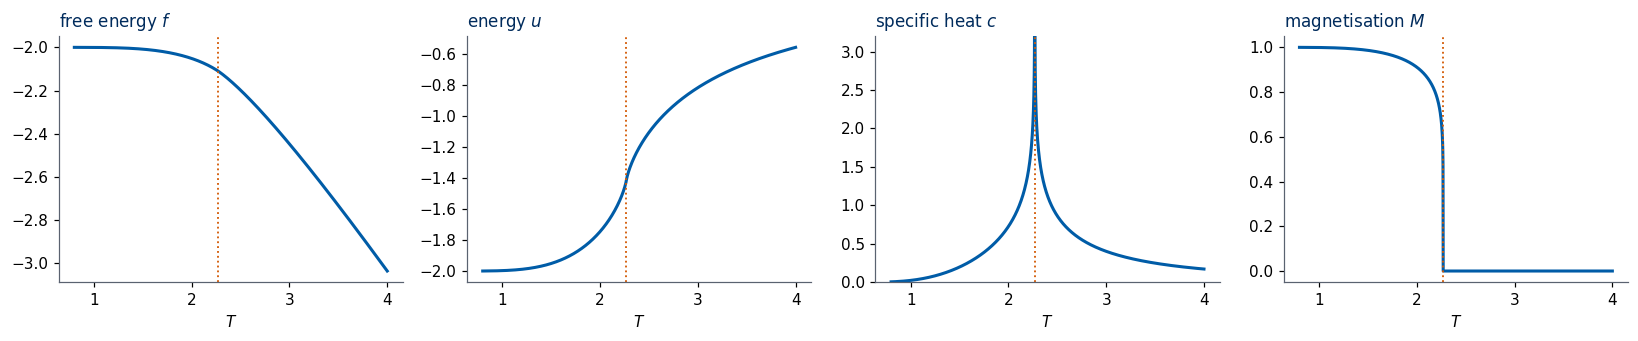

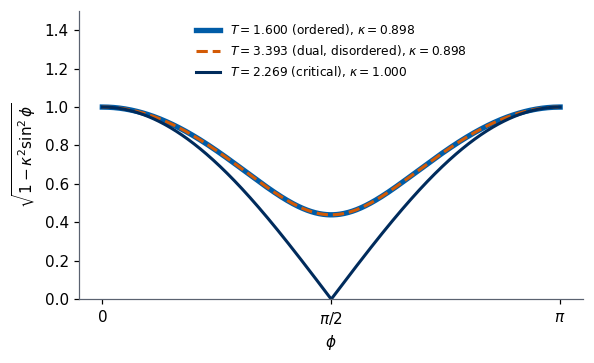

In [27]:
T = np.linspace(0.8, 4.0, 1601); T = T[np.abs(T - TC) > 1e-4]
f = np.array([f_onsager(t) for t in T]); u = u_elliptic(T); c = np.gradient(u, T); M = M_yang(T)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (y, lab) in zip(axes, [(f, "free energy $f$"), (u, "energy $u$"), (c, "specific heat $c$"), (M, "magnetisation $M$")]):
    if y is c:
        for side in (T < TC, T > TC):
            ax.plot(T[side], y[side], color=UJBlue, lw=2)
        ax.set_ylim(0, 3.2)
    else:
        ax.plot(T, y, color=UJBlue, lw=2)
    ax.axvline(TC, color=DSOrange, ls=":", lw=1.2); ax.set_xlabel("$T$"); ax.set_title(lab, loc="left")
plt.tight_layout(); plt.show()

phi_ = np.linspace(0, np.pi, 801)
T1 = 1.6; T1d = 1 / K_dual(1 / T1)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for Tv, col, ls, lw, name in [(T1, UJBlue, "-", 3.5, "ordered"), (T1d, DSOrange, "--", 2, "dual, disordered"), (TC, UJNavy, "-", 2, "critical")]:
    k = kappa(1 / Tv)
    ax.plot(phi_, np.sqrt(np.clip(1 - k**2 * np.sin(phi_)**2, 0, None)), color=col, ls=ls, lw=lw,
            label=rf"$T={Tv:.3f}$ ({name}), $\kappa={k:.3f}$")
ax.set_xticks([0, np.pi / 2, np.pi], ["0", r"$\pi/2$", r"$\pi$"]); ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\sqrt{1-\kappa^2\sin^2\phi}$"); ax.set_ylim(0, 1.5); ax.legend(frameon=False, fontsize=8, loc="upper center")
plt.tight_layout(); plt.show()

**Reading the figures.** $f$ looks perfectly smooth; $u$ is continuous but has a vertical tangent at $T_c$; $c = du/dT$ diverges on both sides; $M$ drops to zero
continuously but very steeply (exponent $1/8$). The singularity of $f$ is in its **second** derivative, and $u$ has no jump (no latent heat): a continuous,
or second-order, transition. The last figure shows the integrand of Onsager's formula: at $T$ and its dual $T^*$ it is identical (Section 5), and at $T_c$ it touches
zero at $\phi=\pi/2$ with a kink.

<hr/>
## 7. The energy at the critical point: $u(T_c) = -\sqrt2$

The value of $u$ at $T_c$ is a good test of the whole construction: we obtain it once from Onsager's solution and once from duality alone, without the solution.
It also shows how much information a symmetry carries.

### 7.1 From Onsager's solution
At $T_c$: $\sinh 2K_c = 1 \Rightarrow \cosh^2 2K_c = 1+\sinh^22K_c = 2 \Rightarrow \tanh^22K_c = \tfrac12$, so $2\tanh^22K_c - 1 = 0$.
In the elliptic formula this prefactor multiplies the divergent $K_1(\kappa\to1)$; their product vanishes (a linear zero times a logarithmic divergence), so
$u(T_c) = -\coth2K_c = -\cosh 2K_c/\sinh 2K_c = -\sqrt2$. Numerically, approaching $T_c$ from both sides:

In [28]:
# SymPy: the prefactor vanishes and coth 2K_c = sqrt 2
Kc_sym = sp.log(1 + sp.sqrt(2)) / 2
print("2 tanh^2 2K_c - 1 =", sp.simplify((2 * sp.tanh(2 * Kc_sym)**2 - 1).rewrite(sp.exp)))
print("-coth 2K_c        =", sp.radsimp(sp.simplify((-1 / sp.tanh(2 * Kc_sym)).rewrite(sp.exp))))

2 tanh^2 2K_c - 1 = 0
-coth 2K_c        = -sqrt(2)


In [29]:
for eps in (1e-3, 1e-6, 1e-9):
    print(f"u(T_c (1 -/+ {eps:.0e})) = {u_elliptic(TC*(1-eps)):.10f}, {u_elliptic(TC*(1+eps)):.10f}")
print(f"-sqrt(2)                = {-np.sqrt(2):.10f}")
b, db = KC, 1e-5
u_int = ((b + db) * f_onsager(1/(b + db)) - (b - db) * f_onsager(1/(b - db))) / (2 * db)
print(f"from the integral, central difference in beta at T_c: {u_int:.8f}")

u(T_c (1 -/+ 1e-03)) = -1.4223925854, -1.4060346096
u(T_c (1 -/+ 1e-06)) = -1.4142294932, -1.4141976315
u(T_c (1 -/+ 1e-09)) = -1.4142135861, -1.4142135387
-sqrt(2)                = -1.4142135624
from the integral, central difference in beta at T_c: -1.41421356


### 7.2 From duality alone, without Onsager's formula
**Step 1 — energy as a derivative.** Since $\varphi = \ln Z/N$ and $\partial\ln Z/\partial\beta = -\langle H\rangle$, with $J=1$ we have $K=\beta$ and
$$
\varphi'(K) = -u(K) \equiv \varepsilon(K),
$$
where $\varepsilon = 2\langle s_is_j\rangle_{\rm nn}$ is twice the nearest-neighbour correlation (two bonds per spin).

**Step 2 — differentiate the duality identity.** Differentiating $\ \varphi(K) - \ln2 - 2\ln\cosh K = \varphi(K^*) - 2K^*\ $ with respect to $K$ (chain rule on the right):
$$
\varepsilon(K) - 2\tanh K = \big(\varepsilon(K^*) - 2\big)\frac{dK^*}{dK}.
$$

**Step 3 — the derivative of the map.** From $e^{-2K^*} = \tanh K$: $\ -2e^{-2K^*}dK^* = \frac{dK}{\cosh^2K}$, so
$\frac{dK^*}{dK} = -\frac{1}{2\tanh K\cosh^2K} = -\frac{1}{2\sinh K\cosh K} = -\frac{1}{\sinh 2K}$, which equals $-1$ at $K_c$.

**Step 4 — evaluate at the self-dual point.** At $K = K^* = K_c$, and **if $u$ is continuous there** (no latent heat, as Section 6 showed):
$$
\varepsilon - 2\tanh K_c = -(\varepsilon - 2)\ \Rightarrow\ \varepsilon(K_c) = 1 + \tanh K_c .
$$
Finally $\tanh K_c = e^{-2K_c}$ (self-duality) $= 1/(1+\sqrt2) = \sqrt2 - 1$, so $\varepsilon(K_c) = \sqrt2$ and $u(T_c) = -\sqrt2$.
Two exact results — $T_c$ and $u(T_c)$ — follow from a symmetry argument. The cell below checks each step, and the differentiated identity also away from $K_c$.

In [30]:
# SymPy: solve Step 4 for epsilon at the self-dual point
eps_s = sp.symbols("epsilon")
Kc_sym = sp.log(1 + sp.sqrt(2)) / 2
sol = sp.solve(sp.Eq(eps_s - 2 * sp.tanh(Kc_sym), -(eps_s - 2)), eps_s)[0]
print("epsilon(K_c) =", sol, "=", sp.radsimp(sp.simplify(sol.rewrite(sp.exp))), ";   u(T_c) = -epsilon(K_c) =", -sp.radsimp(sp.simplify(sol.rewrite(sp.exp))))

epsilon(K_c) = tanh(log(1 + sqrt(2))/2) + 1 = sqrt(2) ;   u(T_c) = -epsilon(K_c) = -sqrt(2)


In [31]:
h = 1e-7
print(f"dK*/dK at K_c (finite difference) = {(K_dual(KC + h) - K_dual(KC - h)) / (2*h):.8f}   (exact: -1/sinh 2K_c = {-1/np.sinh(2*KC):.8f})")
print(f"tanh K_c = {np.tanh(KC):.12f},  e^(-2K_c) = {np.exp(-2*KC):.12f},  sqrt2 - 1 = {np.sqrt(2)-1:.12f}")
print(f"1 + tanh K_c = {1 + np.tanh(KC):.12f}   vs   -u(T_c) from the elliptic formula = {-u_elliptic(TC*(1+1e-12)):.12f}")
# the differentiated identity at several K (not only at K_c), with epsilon from the elliptic formula
for K in (0.3, 0.4, 0.43, 0.45, 0.5, 0.6):
    Ks = K_dual(K)
    lhs = -u_elliptic(1/K) - 2*np.tanh(K)
    rhs = (-u_elliptic(1/Ks) - 2) * (-1/np.sinh(2*K))
    print(f"K = {K:.4f}:  eps(K) - 2 tanh K = {lhs:+.10f}   (eps(K*) - 2) dK*/dK = {rhs:+.10f}")

dK*/dK at K_c (finite difference) = -1.00000000   (exact: -1/sinh 2K_c = -1.00000000)
tanh K_c = 0.414213562373,  e^(-2K_c) = 0.414213562373,  sqrt2 - 1 = 0.414213562373
1 + tanh K_c = 1.414213562373   vs   -u(T_c) from the elliptic formula = 1.414213562342
K = 0.3000:  eps(K) - 2 tanh K = +0.1218738459   (eps(K*) - 2) dK*/dK = +0.1218738459
K = 0.4000:  eps(K) - 2 tanh K = +0.3461812792   (eps(K*) - 2) dK*/dK = +0.3461812792
K = 0.4300:  eps(K) - 2 tanh K = +0.4897691028   (eps(K*) - 2) dK*/dK = +0.4897691028
K = 0.4500:  eps(K) - 2 tanh K = +0.6692477955   (eps(K*) - 2) dK*/dK = +0.6692477955
K = 0.5000:  eps(K) - 2 tanh K = +0.8213302608   (eps(K*) - 2) dK*/dK = +0.8213302608
K = 0.6000:  eps(K) - 2 tanh K = +0.8349870437   (eps(K*) - 2) dK*/dK = +0.8349870437


<hr/>
## 8. Critical exponents

$T_c$ depends on the lattice (Section 10 shows a different value for the triangular lattice). What does *not* depend on such details is the way quantities
diverge or vanish near $T_c$: the **critical exponents**. They are the numbers that characterise a phase transition, and they are what the exact solution
contributes beyond $T_c$. With the reduced temperature $t = (T-T_c)/T_c$ they are defined by
$$
c\sim|t|^{-\alpha},\qquad M\sim(-t)^{\beta}\ (t<0),\qquad \chi\sim|t|^{-\gamma},\qquad \xi\sim|t|^{-\nu},\qquad \langle s_0s_r\rangle\sim r^{-(d-2+\eta)}\ \text{at } T_c ,
$$
where $\chi=\partial m/\partial h$ is the magnetic susceptibility and $d$ the dimension ($d=2$ here, so $\langle s_0s_r\rangle\sim r^{-\eta}$ at $T_c$).
($\beta$ here is an exponent, not $1/T$; the context makes the meaning clear.) $\alpha=0$ with a logarithm, $c\sim-\ln|t|$, is the case of the 2D Ising model.

**Magnetisation, $M\sim(-t)^\beta$.** We fit $\ln M$ against $\ln(-t)$ close to $T_c$ and look at the *local* slope $d\ln M/d\ln(-t)$, which must tend to $\beta$.

**Specific heat, $c\sim -A\ln|t|$.** We fit $c = -A\ln|t| + B_\pm$ on both sides of $T_c$. The amplitude from Onsager's solution is
$A = \frac{2}{\pi}\big(\frac{2}{T_c}\big)^2 = \frac{2}{\pi}(2K_c)^2$ [Onsager 1944]; we test it. $c$ is obtained from the elliptic $u$ by a central difference with a step much smaller than $|T-T_c|$.

beta from a fit of ln M vs ln(-t), |t| < 1e-4:  0.124999    (1/8 = 0.125)
local slope d lnM / d ln|t| at |t| = 1e-2, 1e-4, 1e-6, 1e-8: 0.12310, 0.12498, 0.12500, 0.12500
T < T_c:  c = -A ln|t| + B  with  A = 0.494517,  B = -0.3060
T > T_c:  c = -A ln|t| + B  with  A = 0.494656,  B = -0.3078
exact amplitude: A = (2/pi)(2/T_c)^2 = 0.494539


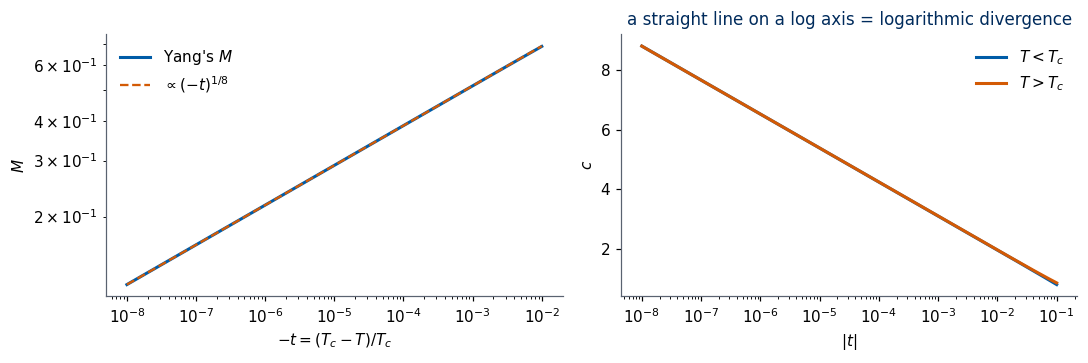

In [32]:
tt = np.logspace(-8, -2, 40)                                   # |t|
Mt = M_yang(TC * (1 - tt))
slope_fit = np.polyfit(np.log(tt[tt < 1e-4]), np.log(Mt[tt < 1e-4]), 1)[0]
local = np.gradient(np.log(Mt), np.log(tt))
print(f"beta from a fit of ln M vs ln(-t), |t| < 1e-4:  {slope_fit:.6f}    (1/8 = {1/8})")
print("local slope d lnM / d ln|t| at |t| = 1e-2, 1e-4, 1e-6, 1e-8:",
      ", ".join(f"{np.interp(np.log(x), np.log(tt), local):.5f}" for x in (1e-2, 1e-4, 1e-6, 1e-8)))

def c_exact(T, rel=1e-4):
    # c = du/dT by a central difference with step rel*|T - T_c|
    hstep = rel * np.abs(T - TC)
    return (u_elliptic(T + hstep) - u_elliptic(T - hstep)) / (2 * hstep)

A_exact = 2 / np.pi * (2 / TC)**2
for side, sgn in (("T < T_c", -1), ("T > T_c", +1)):
    tfit = np.logspace(-9, -4, 30)
    cfit = c_exact(TC * (1 + sgn * tfit))
    A, B = np.polyfit(-np.log(tfit), cfit, 1)
    print(f"{side}:  c = -A ln|t| + B  with  A = {A:.6f},  B = {B:+.4f}")
print(f"exact amplitude: A = (2/pi)(2/T_c)^2 = {A_exact:.6f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].loglog(tt, Mt, color=UJBlue, lw=2, label="Yang's $M$")
ax[0].loglog(tt, tt**0.125 * Mt[0] / tt[0]**0.125, color=DSOrange, ls="--", lw=1.5, label=r"$\propto(-t)^{1/8}$")
ax[0].set_xlabel(r"$-t = (T_c - T)/T_c$"); ax[0].set_ylabel("$M$"); ax[0].legend(frameon=False)
tl = np.logspace(-8, -1, 200)
ax[1].semilogx(tl, c_exact(TC * (1 - tl)), color=UJBlue, lw=2, label="$T<T_c$")
ax[1].semilogx(tl, c_exact(TC * (1 + tl)), color=DSOrange, lw=2, label="$T>T_c$")
ax[1].set_xlabel(r"$|t|$"); ax[1].set_ylabel("$c$"); ax[1].legend(frameon=False)
ax[1].set_title("a straight line on a log axis = logarithmic divergence")  # the two sides nearly coincide: B_- and B_+ are close
plt.tight_layout(); plt.show()

### 8.1 Exponents $\eta$ and $\nu$ from the transfer matrix
The strips of Section 3 give two more exponents, independently of Onsager's formula. Both rest on the idea of *finite-size scaling*: near $T_c$ the only relevant
lengths are $\xi$ and the strip width $L$, so dimensionless quantities depend on their ratio.

* **$\eta$.** At $T_c$ the strip correlation length is proportional to the width. Conformal invariance of the critical point fixes the constant:
  $\xi_L = L/(\pi\eta)$ on a periodic strip [Cardy 1984]. So $\eta_L = L/(\pi\,\xi_L(T_c))$ should tend to $\eta$; the exact value is $\eta = 1/4$.
* **$\nu$.** Near $T_c$, $\xi_L/L$ is a function of $L/\xi\propto L\,|t|^{\nu}$, i.e. of $L^{1/\nu}t$ only, so its slope at $T_c$ grows as
  $\frac{d(\xi_L/L)}{dT}\big|_{T_c}\propto L^{1/\nu}$. The exact value is $\nu = 1$ (Section 6.2: $\xi\propto1/(T-T_c)$).
* **Free energy at $T_c$.** It converges as $f_L - f = -\frac{\pi\,c_{\rm CFT}\,T_c}{6L^2}$ [Blöte, Cardy & Nightingale 1986; Affleck 1986], where $c_{\rm CFT}$ is the central charge
  of the conformal field theory (CFT) describing the critical point; $c_{\rm CFT} = \frac12$ for the Ising model, so $L^2(f_L - f)\to-\pi T_c/12$.

In [33]:
print(" L    eta_L = L/(pi xi_L(T_c))   L^2 (f_L - f)(T_c)    slope d(xi_L/L)/dT at T_c")
slopes, Lv = [], [4, 6, 8, 10, 12]
t0 = time.perf_counter()
for L in Lv:
    l0, l1 = lambda01(L, KC)
    xi = 1 / np.log(l0 / l1)
    dT = 1e-4
    s = (xi_over_L(L, TC + dT) - xi_over_L(L, TC - dT)) / (2 * dT)
    slopes.append(abs(s))
    print(f"{L:2d}       {L/(np.pi*xi):.6f}               {L**2 * (-TC*np.log(l0)/L - f_onsager(TC)):+.6f}            {s:+.4f}")
print(f"(computed in {time.perf_counter()-t0:.1f} s)        -pi T_c/12 = {-np.pi*TC/12:.6f}")
inv_nu = np.diff(np.log(slopes)) / np.diff(np.log(Lv))
print("1/nu from consecutive pairs of L:", ", ".join(f"{v:.4f}" for v in inv_nu))

 L    eta_L = L/(pi xi_L(T_c))   L^2 (f_L - f)(T_c)    slope d(xi_L/L)/dT at T_c
 4       0.257845               -0.620440            -2.3677
 6       0.253121               -0.604507            -3.6854
 8       0.251679               -0.599671            -4.9703
10       0.251056               -0.597589            -6.2438


12       0.250727               -0.596492            -7.5122
(computed in 3.5 s)        -pi T_c/12 = -0.594071
1/nu from consecutive pairs of L: 1.0912, 1.0397, 1.0222, 1.0144


All three columns converge, monotonically in $L$, towards the exact values $\eta = 1/4$, $\nu = 1$ and the conformal prediction $-\pi T_c/12$.
The exponents are not independent. Two *scaling relations* [Kardar 2007], the Fisher relation $\gamma = \nu(2-\eta)$ and the Rushbrooke relation $\alpha + 2\beta + \gamma = 2$,
give the remaining exponent $\gamma$ and a consistency check:

In [34]:
nu, eta, alpha, beta_ = 1, 0.25, 0, 0.125
gamma = nu * (2 - eta)
print(f"gamma = nu (2 - eta) = {gamma}   (= 7/4);   Rushbrooke check alpha + 2 beta + gamma = {alpha + 2*beta_ + gamma}")

gamma = nu (2 - eta) = 1.75   (= 7/4);   Rushbrooke check alpha + 2 beta + gamma = 2.0


<hr/>
## 9. Mean-field theory against the exact solution

Mean-field theory is the approximation one uses when no exact solution exists. The exact solution lets us measure precisely what it gets wrong and why.

**The approximation.** Spin $i$ interacts with its $z$ neighbours ($z=4$ on the square lattice) through $-Js_i\sum_{j\in{\rm nn}(i)}s_j$. Mean-field theory replaces
each neighbour by its average $m=\langle s_j\rangle$: spin $i$ then feels an effective field $zJm$, and a single spin in a field $B$ has
$\langle s\rangle = \tanh(\beta B)$. Self-consistency ($\langle s_i\rangle = m$) gives, with $J=1$,
$$
m = \tanh\Big(\frac{zm}{T}\Big) = \tanh\Big(\frac{4m}{T}\Big).
$$
**Solutions.** $m = 0$ is always a solution. A non-zero one exists when the slope of the right-hand side at $m = 0$ exceeds 1, i.e. $4/T > 1$: $T_c^{\rm MF} = z = 4$.
Near $T_c^{\rm MF}$, $\tanh x\approx x - x^3/3$ gives $m \approx \frac4Tm - \frac13\big(\frac4T\big)^3m^3$, i.e. $m^2\approx 3\big(\frac4T-1\big)\big/\big(\frac4T\big)^3$,
so $m\sim(1 - T/T_c^{\rm MF})^{1/2}$: $\beta_{\rm MF} = \frac12$.
**Energy.** Replacing $s_is_j$ by $m^2$ in each of the $zN/2$ bonds, $u_{\rm MF} = -\frac z2m^2 = -2m^2$: zero above $T_c^{\rm MF}$ and with a finite slope below — a **jump** in $c$
instead of a divergence.

**What is neglected.** The replacement assumes $\langle s_is_j\rangle = \langle s_i\rangle\langle s_j\rangle$: no correlations. Near $T_c$ the correlation length diverges and the
correlated fluctuations dominate, so the approximation must fail there. In 1D ($z=2$) it even predicts a transition at $T=2$, where the exact chain has none (Section 2).
Mean-field exponents become exact only in high dimensions, above the upper critical dimension $d=4$ of the Ising model [Kardar 2007].

In [35]:
# SymPy: m tanh-expansion near T_c^MF, with a = z/T = 4/T
m, a = sp.symbols("m a", positive=True)
cubic = sp.series(sp.tanh(a * m), m, 0, 4).removeO()                     # a m - a^3 m^3 / 3
print("tanh(a m) =", cubic, "+ O(m^5)")
print("non-zero solution of m = a m - a^3 m^3/3:  m =", sp.solve(sp.Eq(cubic / m, 1), m))

tanh(a m) = -a**3*m**3/3 + a*m + O(m^5)
non-zero solution of m = a m - a^3 m^3/3:  m = [sqrt(3)*sqrt(a - 1)/a**(3/2)]


T_c (mean field, numerical) = 4.000000     exact 2D: T_c = 2.269185     ratio = 1.7627
beta_MF from a fit near T_c^MF: 0.49998
mean-field specific heat just below T_c^MF: 1.49640, 1.49996   (and exactly 0 above)


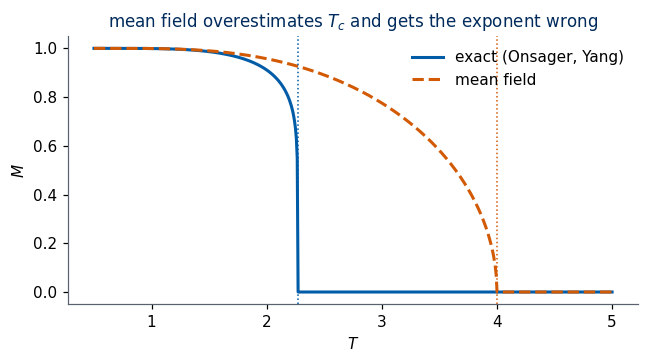

In [36]:
def m_meanfield(T):
    # largest solution of m = tanh(4 m / T)
    if 4 / T <= 1:
        return 0.0
    return brentq(lambda m: m - np.tanh(4 * m / T), 1e-12, 1.0)

# T_c^MF: the largest T with a non-zero solution (found by bisection, threshold m > 1e-6)
lo, hi = 2.0, 6.0
for _ in range(80):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if m_meanfield(mid) > 1e-6 else (lo, mid)
print(f"T_c (mean field, numerical) = {lo:.6f}     exact 2D: T_c = {TC:.6f}     ratio = {lo/TC:.4f}")

tt = np.logspace(-8, -3, 20)
mf = np.array([m_meanfield(4 * (1 - x)) for x in tt])
print(f"beta_MF from a fit near T_c^MF: {np.polyfit(np.log(tt), np.log(mf), 1)[0]:.5f}")
cm = [(-2*m_meanfield(4*(1-x))**2 + 2*m_meanfield(4*(1-2*x))**2) / (4*x) for x in (1e-3, 1e-5)]
print("mean-field specific heat just below T_c^MF:", ", ".join(f"{v:.5f}" for v in cm), "  (and exactly 0 above)")

T = np.linspace(0.5, 5, 600)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(T, M_yang(T), color=UJBlue, lw=2, label="exact (Onsager, Yang)")
ax.plot(T, [m_meanfield(t) for t in T], color=DSOrange, lw=2, ls="--", label="mean field")
ax.axvline(TC, color=UJBlue, ls=":", lw=1); ax.axvline(4, color=DSOrange, ls=":", lw=1)
ax.set_xlabel("$T$"); ax.set_ylabel("$M$"); ax.legend(frameon=False)
ax.set_title("mean field overestimates $T_c$ and gets the exponent wrong")
plt.tight_layout(); plt.show()

Mean field neglects fluctuations; in 2D they are strong: they lower $T_c$ from $4$ to $2.269$ and change $\beta$ from $\frac12$ to $\frac18$ and the jump in $c$ into a
logarithmic divergence. The same self-consistency equation $m=\tanh(\cdot)$ reappears in the energy-based models of the course, as the update rule of a recurrent
$\tanh$ network.

<hr/>
## 10. Universality: the triangular lattice

Section 8 claimed that exponents, unlike $T_c$, do not depend on lattice details. We test this on a different lattice. Exponents depend only on the dimension,
the symmetry of the order parameter (here $s\to-s$) and the range of the interactions [Kardar 2007]; models sharing these form a **universality class**.

Add one diagonal bond to every plaquette: each spin now has $z = 6$ neighbours and the lattice is triangular. In the transfer matrix this is the extra term $K\sum_is_is'_{i+1}$
(flag `lattice="triangular"`; $\mathsf V$ is no longer symmetric, so we use a general eigensolver). The exact critical temperature is $T_c^{\triangle} = 4/\ln3$ [Houtappel 1950],
and the exponents should be those of the square lattice. We test both with the crossing method of Section 3 and with $\eta_L$ of Section 8.1.

Geometry: in the triangular lattice the columns are $\sqrt3/2$ apart (the sites of one column are at distance 1), so the physical correlation length
is $\frac{\sqrt3}{2}\xi_L$ and $\eta_L = L\big/\big(\pi\,\tfrac{\sqrt3}{2}\xi_L\big)$.

In [37]:
print(" L, L+2   crossing T*(L)     eta at the crossing")
t0 = time.perf_counter()
for L in (4, 6, 8, 10):
    Tx = brentq(lambda T: xi_over_L(L, T, "triangular") - xi_over_L(L + 2, T, "triangular"), 3.0, 4.2, xtol=1e-12)
    xi = xi_over_L(L + 2, Tx, "triangular") * (L + 2)
    print(f"{L:2d}, {L+2:2d}   {Tx:.8f}       {(L + 2) / (np.pi * np.sqrt(3) / 2 * xi):.5f}")
print(f"4/ln 3 = {4/np.log(3):.8f}    ({time.perf_counter()-t0:.1f} s)")

 L, L+2   crossing T*(L)     eta at the crossing
 4,  6   3.64236593       0.25076
 6,  8   3.64117712       0.25016


 8, 10   3.64101598       0.25006


10, 12   3.64097803       0.25002
4/ln 3 = 3.64095691    (20.9 s)


The critical temperature is different (more neighbours, more order), the exponent $\eta$ is the same: $T_c$ is a lattice detail, the exponents are
universal. A network trained on one lattice can transfer to another lattice only to the extent that it has learned something universal — the
interpretability question raised in the lecture.

<hr/>
## 11. Summary

| statement | where it is derived and checked |
|---|---|
| all thermodynamics from $\ln Z$; $c$ = energy variance; finite lattice ⇒ $\ln Z$ analytic | Section 1 (brute force, $4\times4$) |
| $Z = \operatorname{Tr}\mathsf T^N$, $\lambda_\pm = 2\cosh K, 2\sinh K$, $\xi_{1D}=-1/\ln\tanh K$ finite: no transition in 1D | Section 2 |
| $Z=\operatorname{Tr}\mathsf V^{L'}$, $f_L\to f$, $c_L$ peak grows, $\xi_L/L$ crossings $\to T_c$; 1D vs 2D, domain walls | Section 3 |
| closed graphs and domain walls: $1 + Nt^4 + 2Nt^6$ and $1+Nx^4+2Nx^6$ | Section 4 |
| $\sinh2K\sinh2K^* = 1$, $\kappa(K) = \kappa(K^*)$, $\sinh 2K_c = 1$ | Section 5 |
| Pauli form, Jordan–Wigner fermions, $2\times2$ blocks, Kaufman's $\lambda_0,\lambda_1$; gap $2\lvert K-K^*\rvert$; $u$ from the integral = elliptic formula | Section 6 |
| $u(T_c) = -\sqrt2$, also from duality | Section 7 |
| $\beta = 1/8$, $\alpha = 0$ (log, amplitude), $\eta = 1/4$, $\nu = 1$, $\gamma=7/4$ | Section 8 |
| $T_c^{\rm MF} = 4$, $\beta_{\rm MF} = 1/2$, jump in $c$ | Section 9 |
| triangular lattice: $T_c = 4/\ln3$, same $\eta$ | Section 10 |
<hr/>
## Exercises

### Exercise 1 — the 1D chain in a field
Using the transfer matrix, compute the magnetisation per spin of the infinite chain, $m = \partial\ln\lambda_+/\partial\tilde h$, numerically (finite
difference) and compare with the closed form $m = \dfrac{\sinh\tilde h}{\sqrt{\sinh^2\tilde h + e^{-4K}}}$. Plot $m(h)$ at several $T$: is there a
spontaneous magnetisation at $h\to0^+$ for any $T>0$?

#### Solution

K = 0.5, beta h = 0.1:  m numerical = 0.26271701,  closed form = 0.26271701
K = 1.0, beta h = 0.05:  m numerical = 0.34668443,  closed form = 0.34668443
K = 2.0, beta h = 0.01:  m numerical = 0.47921470,  closed form = 0.47921470


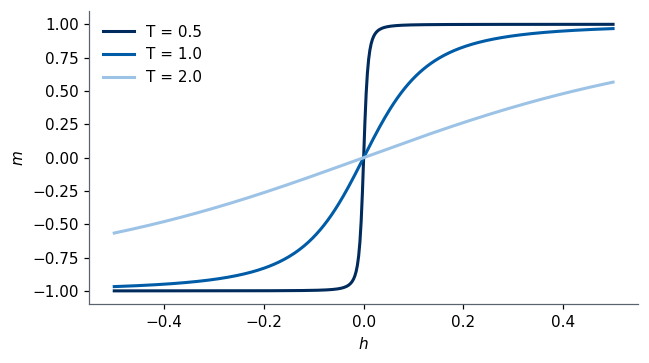

In [38]:
def lam_plus(K, ht):
    return np.exp(K) * np.cosh(ht) + np.sqrt(np.exp(2 * K) * np.sinh(ht)**2 + np.exp(-2 * K))

for K, ht in [(0.5, 0.1), (1.0, 0.05), (2.0, 0.01)]:
    d = 1e-6
    m_num = (np.log(lam_plus(K, ht + d)) - np.log(lam_plus(K, ht - d))) / (2 * d)
    m_cf = np.sinh(ht) / np.sqrt(np.sinh(ht)**2 + np.exp(-4 * K))
    print(f"K = {K}, beta h = {ht}:  m numerical = {m_num:.8f},  closed form = {m_cf:.8f}")

hgrid = np.linspace(-0.5, 0.5, 401)
fig, ax = plt.subplots(figsize=(6, 3.4))
for T, col in [(0.5, UJNavy), (1.0, UJBlue), (2.0, "#9CC3E6")]:
    K = 1 / T; ht = hgrid / T
    ax.plot(hgrid, np.sinh(ht) / np.sqrt(np.sinh(ht)**2 + np.exp(-4 * K)), color=col, lw=2, label=f"T = {T}")
ax.set_xlabel("$h$"); ax.set_ylabel("$m$"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

$m(h)$ is a smooth odd function, $m(0) = 0$ for every $T>0$: no spontaneous magnetisation, only an ever steeper curve as $T\to0$
(the slope at $h = 0$ is $\beta e^{2K}$: it grows exponentially in $K$, but is finite for every $T>0$).

### Exercise 2 — the specific-heat peak of strips
Using `strip` from Section 3, plot the maximum of $c_L$ against $\ln L$. A logarithmic divergence $c\sim-A\ln|t|$ combined with $|t|\sim1/L$
(because $\nu = 1$) predicts $c_{\max}(L)\approx A\ln L + \text{const}$. Fit the slope and compare with $A$ found in Section 8.

#### Solution

In [39]:
cmax = []
t0 = time.perf_counter()
Lex = [4, 6, 8, 10, 12]
for L in Lex:
    if L in strip:
        cmax.append(strip[L]["c"][2:-2].max())
    else:                                     # L = 12 was not in the scan: maximise c_L near its peak
        def cL(T, L=L, d=2e-3):
            fm, f0, fp = (-(T + s) * np.log(lambda01(L, 1 / (T + s))[0]) / L for s in (-d, 0, d))
            return -T * (fp - 2 * f0 + fm) / d**2
        from scipy.optimize import minimize_scalar
        res = minimize_scalar(lambda T: -cL(T), bounds=(2.24, 2.30), method="bounded", options={"xatol": 1e-3})
        cmax.append(-res.fun)
print(f"(L = 12 peak search: {time.perf_counter()-t0:.1f} s)")
slope = np.polyfit(np.log(Lex[1:]), cmax[1:], 1)[0]
for L, cm in zip(Lex, cmax):
    print(f"L = {L:2d}: c_max = {cm:.4f}")
print(f"slope of c_max vs ln L (L = 6..12): {slope:.4f};   A from Section 8: {A_exact:.4f}")

(L = 12 peak search: 18.2 s)
L =  4: c_max = 0.8728
L =  6: c_max = 1.0739
L =  8: c_max = 1.2160
L = 10: c_max = 1.3262
L = 12: c_max = 1.4170
slope of c_max vs ln L (L = 6..12): 0.4947;   A from Section 8: 0.4945


The slope approaches $A$ as $L$ grows (the small strips still carry visible corrections). The specific-heat peak of a finite lattice grows only
**logarithmically** with its size — one reason why a Monte Carlo study (and the CNN of Lab 011) sees a broad, shifted feature rather than a sharp
singularity.

### Exercise 3 (open) — the quantum connection
Section 6.1 used the identity $e^{K}\mathbb 1 + e^{-K}\sigma^x = \sqrt{2\sinh2K}\;e^{K^*\sigma^x}$ to write the strip transfer matrix as
$\mathsf V = (2\sinh2K)^{L/2}\,\mathsf V_2^{1/2}\mathsf V_1\mathsf V_2^{1/2}$: a classical Ising coupling along the column and a **transverse field** of strength $K^*$.
Prove the identity and verify it numerically for a few values of $K$. This is the bridge to the transverse-field Ising chain used later in the course.

#### Solution

In [40]:
sx = np.array([[0.0, 1.0], [1.0, 0.0]])
from scipy.linalg import expm
for K in (0.2, KC, 0.8):
    lhs = np.exp(K) * np.eye(2) + np.exp(-K) * sx
    rhs = np.sqrt(2 * np.sinh(2 * K)) * expm(K_dual(K) * sx)
    print(f"K = {K:.4f}:  max |lhs - rhs| = {np.abs(lhs - rhs).max():.1e}")

K = 0.2000:  max |lhs - rhs| = 1.1e-16
K = 0.4407:  max |lhs - rhs| = 2.2e-16
K = 0.8000:  max |lhs - rhs| = 1.1e-16


In [41]:
# SymPy: the same identity symbolically (coefficients of 1 and sigma^x)
K = sp.symbols("K", positive=True)
K_star = -sp.log(sp.tanh(K)) / 2
pref = sp.sqrt(2 * sp.sinh(2 * K))
print("coefficient of 1      :", sp.simplify((pref * sp.cosh(K_star) - sp.exp(K)).rewrite(sp.exp)))
print("coefficient of sigma^x:", sp.simplify((pref * sp.sinh(K_star) - sp.exp(-K)).rewrite(sp.exp)))

coefficient of 1      : 0
coefficient of sigma^x: 0


Proof: $e^{K^*\sigma^x} = \cosh K^*\,\mathbb1 + \sinh K^*\sigma^x$ (because $(\sigma^x)^2=\mathbb 1$). The ratio of the coefficients must be $e^{-K}/e^{K}=e^{-2K}$, and indeed
$\tanh K^* = e^{-2K}$ (Section 5). For the prefactor: $\cosh^2K^* = 1/(1-\tanh^2K^*) = 1/(1-e^{-4K}) = e^{2K}/(2\sinh2K)$, so $\sqrt{2\sinh2K}\cosh K^* = e^{K}$.
At the self-dual point $K = K^* = K_c$ the column coupling and the transverse field are equal — the critical point of the quantum chain.